# Ranking US Industries by the Risk of a Severe Drawdown

**Data Science Project — CRISP-DM workflow**

This notebook builds a model that **ranks 48 US industries each month by the risk of a severe price drawdown over the next 24 months**, and turns the ranking into four risk levels for a portfolio manager.

We follow the standard data-science process (CRISP-DM):

1. **Business / Problem Understanding** — define the question and the hypotheses
2. **Data Understanding** — the datasets and their properties
3. **Data Preparation** — cleaning, market-context signals, features, target, leakage tests
4. **Exploratory Data Analysis (EDA)** — visual and statistical exploration
5. **Modeling** — walk-forward comparison of a base rate, a volatility-only benchmark, a Logit and a Random Forest
6. **Evaluation** — risk levels, ROC curve, feature importance
7. **Improving the Model** — bubble signals, market regime, own-history features, other targets and settings
8. **Rigorous Validation** — stability over time, volatility benchmark, signal rules, run-up episodes, acting on the signal
9. **Deployment** — the monthly risk report
10. **Conclusion** — findings, limitations, future work

The product version of the same work, organised by function, is `FDA_Crash_Risk_Advisor_v6.ipynb`. Both notebooks use the same code and data, so their numbers agree.

## 1. Business / Problem Understanding

**Motivation.** A portfolio manager who holds US equities across industries wants to know where the risk of a large fall is concentrated. Greenwood, Shleifer & You (2019) show that an industry whose price has doubled is far more likely to fall by 40% or more afterwards, even though its average return is not lower. This project asks whether that kind of risk can be ranked across industries, every month, using only information available at the time.

**Why ranking, not timing or "bubble detection"?** Earlier versions of this project tried to detect bubbles and to forecast *when* a crash would come. Neither held up out of sample: timing skill was at chance level, and bubble-specific signals added nothing. What did hold up was the **cross-sectional ranking**: which industries are riskier than the others in the same month. We therefore reframe the task:

> **Problem:** Each month, rank the industries by the probability of a **severe drawdown** in the next 24 months, where a severe drawdown is a fall of at least 30% of the industry's price **relative to the market**.

**Hypotheses.**
- **H1:** Features of an industry (past return, volatility, firm entry, valuation) rank industries by severe-drawdown risk better than chance.
- **H2:** A Random Forest on those features ranks better than the traditional measure a client already has, a ranking by volatility.

**Type of task:** supervised **binary classification**, used as a **ranking**. **Primary metric:** XS-AUC, the AUC across industries inside each month, compared with 0.5 (chance) and with a volatility-only benchmark. An XS-AUC of 0.70 means that for a random pair of industries in the same month, where only one goes on to a severe drawdown, the model ranks that one higher 70% of the time. It is not the share of drawdowns predicted correctly.

**Who decides:** the portfolio manager. The output supports a risk review; it does not trade.

## 2. Data Understanding

All data are read from the local `data/` folder (or `data.zip`); nothing is downloaded at run time.

| Dataset | Source | Rows | Description |
|---|---|---|---|
| Industry returns, monthly | Ken French Data Library, 49 industry portfolios | 1,203 months × 48 | Value- and equal-weighted total returns, firm counts, firm size, BE/ME (July 1926 → September 2026) |
| Industry returns, daily | Ken French Data Library | ~26,300 days × 48 | Daily value-weighted returns, used for volatility |
| Market factors | Ken French Data Library | 1,203 months | Mkt-RF, SMB, HML, RF |
| Macro series | FRED | monthly | BAA, AAA, GS10, TB3MS yields and NBER recession months |
| CAPE | Shiller (shillerdata.com) | monthly | Cyclically adjusted price-earnings ratio |

The 49th portfolio, "Other", is dropped, which leaves 48 industries. Returns are **total returns** (dividends reinvested), the equivalent of adjusted prices.

In [1]:
%pip install -q hmmlearn shap xlrd

Note: you may need to restart the kernel to use updated packages.


In [2]:
import warnings
warnings.filterwarnings("ignore")
import io, os, zipfile
import numpy as np
import pandas as pd
from scipy import stats
from IPython.display import display

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import seaborn as sns

import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve
from hmmlearn.hmm import GaussianHMM
import shap

pd.set_option("display.max_columns", 40, "display.width", 250, "display.max_colwidth", None)

In [3]:
# 2.1 Settings: every modelling choice in one place
SEED, TRADING_DAYS = 42, 252
DATA_DIR, FIG_DIR  = "data", "figures"
MKT_NAME = "48-industry market"

# Target (Greenwood, Shleifer & You, 2019)
H_LIST    = [6, 12, 24]        # forecast horizons in months
MAIN_H    = 24                 # headline horizon
REL_DD    = 0.30               # Risk Ranking target: drawdown >= 30% of the industry price divided by the market, within H months
ABS_DD    = 0.40               # Run-up Watch target: drawdown >= 40% of the industry price itself (Greenwood et al.)
RUNUP_2Y, RUNUP_5Y = 1.00, 0.50   # run-up (Greenwood et al.): >= 100% in 2 years, raw and net of market, and >= 50% in 5 years
MIN_FIRMS = 10                 # an industry needs at least 10 firms
MASK_DD12 = -0.20              # "already falling": >= 20% below the 12-month high (not an early-warning month)

# Point-in-time availability of slow data
FRED_LAG, FRED_FFILL = 1, 2    # FRED month M is usable at the end of M+1, carried forward <= 2 months
CAPE_LAG, CAPE_FFILL = 3, 3    # Shiller CAPE earnings arrive about one quarter late
BM_MONTH = 12                  # BE/ME of year Y is usable from the end of December of year Y

# Layer 1: GSADF / PSY
PSY_W0, PSY_TB, N_SIM_PSY = 36, 24, 499  # minimum window, family-wise window (months), wild-bootstrap draws

# Layer 2: HMM
HMM_START, HMM_RT_START = "1950-01-01", 1955   # sample start, first year of real-time regimes
VOL_WINDOW = 21                                # days of realised volatility
REGIMES = ["Low volatility", "Normal volatility", "High volatility"]

# Layer 3: walk-forward
FIRST_TEST_YEAR  = 1960
STAGE1_TEST_YEAR = 1975        # first test year of the market-level model (needs the HMM and macro history)
MIN_TRAIN = 1000               # minimum training rows
HALF_LIFE_GRID = [10, 20, 40, np.inf]   # years; training rows are weighted by 0.5 ** (age / half-life); inf = no decay
VALID_YEARS    = range(1945, 1960)      # the half-life is chosen on these years only, before the test period starts
WINSOR    = (0.01, 0.99)       # continuous features are clipped to these training-set quantiles
MAIN_MODEL, BENCH_MODEL, VOL_MODEL = "RandomForest", "Logit", "Logit-Vol"
EXPLAIN_YEARS = {"Dot-com 2000": 1999, "GFC 2008": 2007, "COVID 2020": 2019, "Rates 2022": 2021}

# Evaluation, alerts and backtest
N_BOOT, BLOCK = 300, 24        # moving-block bootstrap: replications and block length (months)
LEVELS     = ["Low", "Normal", "Elevated", "High"]   # quartiles of the monthly ranking, fixed in advance
RUNUP_GRID = [0.50, 0.75, 1.00, 1.25, 1.50]          # run-up thresholds reported in 7.2; 100% is the pre-specified one
ALERT_K    = 5                 # the 5 highest-ranked industries each month (used in the research tests of Part 11)
COST_BPS   = 10                # trading cost per unit of traded value

REGIME_COLORS = dict(zip(REGIMES, ["#1baf7a", "#eda100", "#e34948"]))
MODEL_COLORS  = {"Logit-Vol": "#9a9994", "Logit": "#2a78d6", "RandomForest": "#eb6834"}
os.makedirs(FIG_DIR, exist_ok=True)

def save(fig, name):
    fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=200, bbox_inches="tight")
    plt.show()

In [4]:
# 2.2 Load the data files
DATA_FILES = ["49_Industry_Portfolios_CSV.zip", "49_Industry_Portfolios_daily_CSV.zip", "F-F_Research_Data_Factors_CSV.zip",
              "BAA.csv", "AAA.csv", "GS10.csv", "TB3MS.csv", "USREC.csv", "ie_data.xls"]

def ensure_data():
    """Make sure every data file is in DATA_DIR. Sources, in order: data.zip next to the notebook, then a Colab upload."""
    missing = lambda: [f for f in DATA_FILES if not os.path.exists(os.path.join(DATA_DIR, f))]
    def unpack(archive):                                            # keep only the expected files, whatever the folder inside
        with zipfile.ZipFile(archive) as z:
            for member in z.namelist():
                if os.path.basename(member) in DATA_FILES:
                    open(os.path.join(DATA_DIR, os.path.basename(member)), "wb").write(z.read(member))
    if not missing():
        return
    os.makedirs(DATA_DIR, exist_ok=True)
    if os.path.exists("data.zip"):
        unpack("data.zip")
    if missing():
        try:
            from google.colab import files
        except ImportError:
            raise FileNotFoundError(f"Missing in '{DATA_DIR}/': {missing()}. Put data.zip or the data folder next to the notebook.")
        for name, content in files.upload().items():                # choose data.zip, or the data files themselves
            if name in DATA_FILES:
                open(os.path.join(DATA_DIR, name), "wb").write(content)
            elif name.lower().endswith(".zip"):
                unpack(io.BytesIO(content))
    assert not missing(), f"Still missing: {missing()}"

ensure_data()

def read_french(fname):
    with zipfile.ZipFile(os.path.join(DATA_DIR, fname)) as z:
        text = z.read(z.namelist()[0]).decode("latin-1").replace("\r", "")
    tables = {}
    for block in text.split("\n\n"):
        lines = block.strip("\n").split("\n")
        h = next((i for i, l in enumerate(lines) if l.startswith(",")), None)   # header row ",col1,col2,..."
        if h is None:
            continue
        df = pd.read_csv(io.StringIO("\n".join(lines[h:])), index_col=0, float_precision="round_trip")
        df.columns = df.columns.str.strip()
        df = df.mask(df <= -99.99)
        idx = df.index.astype(str).str.strip()
        if len(idx[0]) == 6:
            df.index = pd.to_datetime(idx, format="%Y%m") + pd.offsets.MonthEnd(0)
        elif len(idx[0]) == 8:
            df.index = pd.to_datetime(idx, format="%Y%m%d")
        tables[lines[h - 1].strip() if h else ""] = df
    return tables

def read_fred(sid):
    s = pd.read_csv(os.path.join(DATA_DIR, f"{sid}.csv"), index_col=0, parse_dates=True, na_values=".").iloc[:, 0]
    s = s.astype(float).dropna()
    s.index = s.index + pd.offsets.MonthEnd(0)
    return s.rename(sid)

def read_cape():
    x = pd.read_excel(os.path.join(DATA_DIR, "ie_data.xls"), sheet_name="Data", skiprows=7)[["Date", "CAPE"]]
    x = x.apply(pd.to_numeric, errors="coerce").dropna()
    year = x["Date"].astype(int)
    month = ((x["Date"] - year) * 100).round().astype(int)          # 2024.1 = October
    idx = pd.to_datetime(dict(year=year, month=month, day=1)) + pd.offsets.MonthEnd(0)
    return pd.Series(x["CAPE"].values, index=idx, name="CAPE")

ind_tables = read_french("49_Industry_Portfolios_CSV.zip")
day_tables = read_french("49_Industry_Portfolios_daily_CSV.zip")
ff   = next(iter(read_french("F-F_Research_Data_Factors_CSV.zip").values())) / 100   # first table = monthly factors
fred = {sid: read_fred(sid) for sid in ["BAA", "AAA", "GS10", "TB3MS", "USREC"]}
cape = read_cape()

drop_other = lambda t: t.drop(columns="Other")                      # 49 portfolios minus "Other" = 48 industries
ret    = drop_other(ind_tables["Average Value Weighted Returns -- Monthly"]) / 100
ret_ew = drop_other(ind_tables["Average Equal Weighted Returns -- Monthly"]) / 100
nfirms = drop_other(ind_tables["Number of Firms in Portfolios"]).reindex(ret.index)
fsize  = drop_other(ind_tables["Average Firm Size"]).reindex(ret.index)
be_me  = drop_other(ind_tables["Sum of BE / Sum of ME"])
dret   = drop_other(day_tables["Average Value Weighted Returns -- Daily"]) / 100
mkt    = (ff["Mkt-RF"] + ff["RF"]).reindex(ret.index)               # Fama-French market, total return
mcap   = nfirms * fsize                                             # industry market cap ($ million)
INDS   = list(ret.columns)

In [5]:
# 2.3 Market index from the 48 industries, 11 sectors, common end date
GICS_MAP = {
    "Energy":                 ["Coal", "Oil"],
    "Materials":              ["Chems", "Rubbr", "BldMt", "Steel", "Gold", "Mines", "Paper", "Boxes"],
    "Industrials":            ["Cnstr", "FabPr", "Mach", "ElcEq", "Aero", "Ships", "Guns", "BusSv", "Trans", "Whlsl"],
    "Consumer Discretionary": ["Toys", "Clths", "Txtls", "Autos", "PerSv", "Rtail", "Meals"],
    "Consumer Staples":       ["Agric", "Food", "Soda", "Beer", "Smoke", "Hshld"],
    "Health Care":            ["Hlth", "MedEq", "Drugs"],
    "Financials":             ["Banks", "Insur", "Fin"],
    "Information Technology": ["Hardw", "Softw", "Chips", "LabEq"],
    "Communication Services": ["Telcm", "Fun", "Books"],
    "Utilities":              ["Util"],
    "Real Estate":            ["RlEst"],
}
SECTOR_OF = {ind: sec for sec, inds in GICS_MAP.items() for ind in inds}
assert set(INDS) == set(SECTOR_OF), "every industry needs exactly one sector"

w_prev = mcap.shift(1)                                              # market cap at the end of the previous month
w_d = w_prev.set_axis(w_prev.index.to_period("M")).reindex(dret.index.to_period("M")).set_axis(dret.index).where(dret.notna())
mkt_daily = (1 + (dret * w_d).sum(axis=1, min_count=1) / w_d.sum(axis=1, min_count=1)).dropna().cumprod()
sector_ret = pd.DataFrame({sec: (ret[c] * w_prev[c]).sum(axis=1, min_count=1) / w_prev[c].where(ret[c].notna()).sum(axis=1)
                           for sec, c in GICS_MAP.items()}).dropna(how="all")

last_day   = mkt_daily.index[-1]
month_done = (last_day + pd.offsets.BDay(1)).month != last_day.month
END = min(ret.index[-1], last_day + pd.offsets.MonthEnd(0) if month_done else last_day - pd.offsets.MonthEnd(1))
ret, ret_ew, nfirms, mcap, mkt, sector_ret, dret, mkt_daily = [
    x.loc[:END] for x in (ret, ret_ew, nfirms, mcap, mkt, sector_ret, dret, mkt_daily)]
mkt_m     = mkt_daily.resample("ME").last()                         # month-end index level
mkt_ret_d = np.log(mkt_daily).diff().dropna()                       # daily log return on the trading calendar itself
usrec     = fred["USREC"].loc[:END]                                 # NBER recessions: shading and validation only
RF_M      = ff["RF"]                                                # monthly T-bill return

In [6]:
# 2.4 Structure, date ranges and missing values
series = {"ret (monthly)": ret, "ret_ew (monthly)": ret_ew, "dret (daily)": dret, "sector_ret": sector_ret,
          "nfirms": nfirms, "be_me (annual)": be_me, "mkt_daily": mkt_daily, **fred, "CAPE": cape}
for name, x in series.items():
    assert x.index.is_monotonic_increasing and not x.index.has_duplicates, f"{name}: dates must be sorted and unique"
quality = pd.DataFrame({name: {"Start": str(x.index[0])[:10], "End": str(x.index[-1])[:10], "Rows": len(x),
                               "Missing %": 100 * np.isnan(np.asarray(x, dtype=float)).mean()}
                        for name, x in series.items()}).T.astype({"Rows": int, "Missing %": float}).round(2)

chk = pd.concat({"MKT48": mkt_m.pct_change(), "FF": mkt}, axis=1).dropna()
index_check = pd.Series({"Common end date": f"{END:%Y-%m-%d}", "Industries": len(INDS),
                         "Correlation with FF market (monthly)": round(chk.corr().iloc[0, 1], 4),
                         "Mean abs. difference per month (%)": round(100 * (chk["MKT48"] - chk["FF"]).abs().mean(), 3),
                         "Zero daily index returns (%)": round(100 * (mkt_ret_d == 0).mean(), 2),
                         "Industry-months with |return| > 50% (kept)": int((ret.abs() > 0.5).sum().sum())}, name="Value")
display(quality, index_check.to_frame())

,Start,End,Rows,Missing %
ret (monthly),1926-07-31,2026-09-30,1203,4.97
ret_ew (monthly),1926-07-31,2026-09-30,1203,4.97
dret (daily),1926-07-01,2026-09-30,26338,5.32
sector_ret,1926-08-31,2026-09-30,1202,0.00
nfirms,1926-07-31,2026-09-30,1203,0.00
be_me (annual),1926,2026,101,5.07
mkt_daily,1926-08-02,2026-09-30,26313,0.00
BAA,1919-01-31,2026-10-31,1294,0.00
AAA,1919-01-31,2026-10-31,1294,0.00
GS10,1953-04-30,2026-10-31,883,0.00


,Value
Common end date,2026-09-30
Industries,48
Correlation with FF market (monthly),0.9994
Mean abs. difference per month (%),0.095
Zero daily index returns (%),0.0
Industry-months with |return| > 50% (kept),66


In [7]:
# 2.5 Descriptive statistics of monthly returns by sector
def return_summary(r):
    r = r.dropna()
    return pd.Series({"Months": len(r), "Mean %/month": r.mean() * 100, "Ann. vol % (x sqrt12)": r.std() * np.sqrt(12) * 100,
                      "Skew": stats.skew(r), "Excess kurtosis": stats.kurtosis(r), "Min %": r.min() * 100, "Max %": r.max() * 100})

eda = pd.DataFrame({s: return_summary(sector_ret[s]) for s in sector_ret}).T
eda.loc[MKT_NAME] = return_summary(mkt_m.pct_change())
eda.round(2).astype({"Months": int})

,Months,Mean %/month,Ann. vol % (x sqrt12),Skew,Excess kurtosis,Min %,Max %
Energy,1202,1.04,22.27,0.23,4.22,-34.67,39.37
Materials,1202,0.97,21.96,0.69,9.63,-29.06,55.54
Industrials,1202,1.00,22.97,0.64,10.67,-31.78,56.60
Consumer Discretionary,1202,1.06,21.60,0.47,9.54,-31.35,58.54
Consumer Staples,1202,0.93,15.92,-0.05,6.55,-27.34,35.32
Health Care,1202,1.07,19.05,0.08,6.63,-34.76,37.33
Financials,1202,1.02,23.42,0.44,11.32,-40.47,59.44
Information Technology,1202,1.21,22.70,-0.22,2.56,-32.11,33.50
Communication Services,1202,0.82,16.37,-0.14,2.88,-23.02,29.26
Utilities,1202,0.87,18.82,0.11,7.48,-29.72,43.55


**What the raw data shows.**

- **The data are long and complete enough.** Monthly returns run from July 1926 to September 2026. About 5% of industry-months are missing because some industries start later (few listed firms in the early decades); these months are left missing and never filled.
- **The market index we build is the right one.** A cap-weighted index of the 48 industries has a 0.9994 correlation with the Fama–French market return, so "relative to the market" means what it should.
- **Returns are fat-tailed.** Excess kurtosis is far above 0 for every sector (about 7 for the market, above 10 for Industrials and Financials), and 66 industry-months have a return beyond ±50%. Extreme moves are much more common than a normal distribution implies. This is why the target is defined from observed drawdowns and why skill is judged with rank-based metrics and bootstrap intervals rather than normal-theory tests.
- **Sectors differ in risk.** Annualised volatility ranges from about 16% (Consumer Staples, Communication Services) to 33% (Real Estate). Any model of drawdown risk will pick this up, so a volatility-only ranking is the benchmark to beat (H2).

## 3. Data Preparation

Steps:
1. **Market-context signals.** Two descriptive signals are computed first because they are candidate features later: a real-time **GSADF** test for explosive price behaviour in each industry, and a 3-state **HMM** volatility regime of the market.
2. **Feature engineering.** Each industry-month is described with information available at that month only. Continuous features are turned into **cross-sectional percentile ranks**, so they keep the same scale in 1935 and in 2020.
3. **Target label.** `1` if the industry's price relative to the market falls at least 30% from its running peak within the next 24 months.
4. **Panel.** One row per industry-month, with the rows removed at each step reported.
5. **Leakage tests.** Truncation tests prove that the GSADF and HMM signals at month *t* do not use data after *t*.
6. **Train/test split.** Not one split but a **walk-forward**: the model for year *Y* is fitted on data up to the end of year *Y−1*, with an embargo so that a training row is used only when its 24-month outcome was already known (details in §5).

In [8]:
# 3.1 GSADF / PSY test: real-time flag of explosive price behaviour
def bsadf_matrix(Y, w0=PSY_W0):
    # Y: (n_series, T) log prices without NaN. ADF regression: dy_t = a + rho * y_{t-1} + e_t (lag 0)
    S, T = Y.shape
    x, z = Y[:, :-1], np.diff(Y, axis=1)
    csum = lambda a: np.concatenate([np.zeros((S, 1)), np.cumsum(a, axis=1)], axis=1)
    Sx, Sz, Sxx, Szz, Sxz = csum(x), csum(z), csum(x * x), csum(z * z), csum(x * z)
    out = np.full((S, T), np.nan)
    for j in range(w0 - 1, T - 1):
        s = np.arange(0, j - w0 + 2)                                # every admissible window start
        n = (j + 1 - s).astype(float)
        sx, sz = Sx[:, [j + 1]] - Sx[:, s], Sz[:, [j + 1]] - Sz[:, s]
        sxx, szz, sxz = Sxx[:, [j + 1]] - Sxx[:, s], Szz[:, [j + 1]] - Szz[:, s], Sxz[:, [j + 1]] - Sxz[:, s]
        vxx = np.maximum(sxx - sx * sx / n, 1e-12)
        cxz = sxz - sx * sz / n
        rho = cxz / vxx
        ssr = np.maximum((szz - sz * sz / n) - rho * cxz, 1e-12)
        out[:, j + 1] = np.max(rho / np.sqrt(ssr / (n - 2) / vxx), axis=1)
    return out

def run_psy(price, seed=SEED):
    """Point-in-time PSY for one price series. Returns the monthly table and the full-sample GSADF test (ex-post)."""
    logp = np.log(price.dropna())
    y = logp.values - logp.values[0]
    d = np.diff(y)
    e = d - np.cumsum(d) / np.arange(1, len(d) + 1)                 # residual under H0, expanding mean
    g = np.random.default_rng(seed).standard_normal((len(d), N_SIM_PSY)).T
    sims = np.concatenate([np.zeros((N_SIM_PSY, 1)), np.cumsum(e * g, axis=1)], axis=1)
    b = bsadf_matrix(np.vstack([y, sims]))
    sim_max = pd.DataFrame(b[1:].T).rolling(PSY_TB, min_periods=1).max().values.T
    with np.errstate(all="ignore"):
        cv = np.nanquantile(sim_max, 0.95, axis=0)
    out = pd.DataFrame({"BSADF": b[0], "CV": cv}, index=logp.index)
    out["Margin"] = out["BSADF"] - out["CV"]
    out["Bubble"] = ((out["Margin"] > 0) & (logp.diff(12) > 0)).astype(float).where(out["CV"].notna())
    g_stat, sim_g = np.nanmax(b[0]), np.nanmax(b[1:], axis=1)
    gsadf = {"GSADF": g_stat, "CV 95%": np.quantile(sim_g, 0.95), "p-value": (1 + (sim_g >= g_stat).sum()) / (1 + len(sim_g))}
    return out, gsadf

def run_psy_returns(r, seed=SEED):
    """PSY on each continuous run of monthly returns; after a data gap the test starts again, as it would in real time."""
    parts, best = [], (0, None)
    for _, seg in r.dropna().groupby(r.isna().cumsum()[r.notna()]):
        if len(seg) <= PSY_W0 + PSY_TB:
            continue
        base = pd.Series([1.0], index=[seg.index[0] - pd.offsets.MonthEnd(1)])
        res, g = run_psy(pd.concat([base, (1 + seg).cumprod()]), seed=seed)
        parts.append(res)
        if len(seg) > best[0]:
            best = (len(seg), g)
    return pd.concat(parts).reindex(r.index), best[1]

def episodes(flag, min_len=3):
    """Runs of at least `min_len` flagged months: Start, Detected (month the run is confirmed), End, Months."""
    f = flag.fillna(0).astype(bool)
    rows = [(g.index[0], g.index[min_len - 1], g.index[-1], len(g))
            for _, g in f.groupby((f != f.shift()).cumsum()) if g.iloc[0] and len(g) >= min_len]
    return pd.DataFrame(rows, columns=["Start", "Detected", "End", "Months"])

In [9]:
# 3.1b Run the test on each of the 48 industries (flag and signal strength)
ind_psy    = pd.DataFrame(index=ret.index, columns=INDS, dtype=float)   # 0/1 flag
ind_margin = ind_psy.copy()                                             # BSADF - critical value
for i, ind in enumerate(INDS):
    res, _ = run_psy_returns(ret[ind], seed=SEED + 100 + i)
    ind_psy[ind], ind_margin[ind] = res["Bubble"], res["Margin"]
too_few = nfirms < MIN_FIRMS
ind_psy, ind_margin = ind_psy.mask(too_few), ind_margin.mask(too_few)
pd.Series({"Industry-months with a PSY result": int(ind_psy.notna().sum().sum()),
           "Share flagged as bubble": round(ind_psy.stack().mean(), 4),
           "Industries with a data gap (PSY restarted)": int(((ret.notna() & ret.shift().isna()).sum() > 1).sum())},
          name="Value", dtype=object).to_frame()

,Value
Industry-months with a PSY result,42022
Share flagged as bubble,0.0644
Industries with a data gap (PSY restarted),1


In [10]:
# 3.2 HMM volatility regime: refit every year, forward-filtered (no smoothing with future data)
hmm_df = pd.DataFrame({"Return": mkt_ret_d})
hmm_df["Log_Vol"] = np.log(hmm_df["Return"].rolling(VOL_WINDOW).std() * np.sqrt(TRADING_DAYS))
warmup = int(hmm_df.loc[HMM_START:END, "Log_Vol"].isna().sum())     # rows lost to the rolling window (reported in 3.2)
hmm_df = hmm_df.loc[HMM_START:END].dropna()
VOL_COL = 1

def fit_hmm(X, K=3, seeds=(0,), init=None):
    """Highest log-likelihood over random starts, plus a warm start from last year's model."""
    cands = []
    if init is not None:
        m = GaussianHMM(n_components=K, covariance_type="full", n_iter=200, tol=1e-4, random_state=0, init_params="")
        m.startprob_, m.transmat_ = init.startprob_.copy(), init.transmat_.copy()
        m.means_, m.covars_ = init.means_.copy(), init.covars_.copy()
        cands.append(m)
    cands += [GaussianHMM(n_components=K, covariance_type="full", n_iter=200, tol=1e-4, random_state=s) for s in seeds]
    best, best_ll = None, -np.inf
    for m in cands:
        try:
            ll = m.fit(X).score(X)
        except Exception:
            continue
        if np.isfinite(ll) and ll > best_ll:
            best, best_ll = m, ll
    return best

def hmm_filter(model, X):
    """Forward filter: P(state_t | data up to t)."""
    K = model.n_components
    log_b = np.column_stack([stats.multivariate_normal(model.means_[k], model.covars_[k], allow_singular=True).logpdf(X)
                             for k in range(K)])
    alpha = np.zeros((len(X), K))
    a = model.startprob_ * np.exp(log_b[0] - log_b[0].max())
    alpha[0] = a / a.sum()
    for t in range(1, len(X)):
        a = (alpha[t - 1] @ model.transmat_) * np.exp(log_b[t] - log_b[t].max())
        alpha[t] = a / a.sum() if a.sum() > 0 else alpha[t - 1] @ model.transmat_
    return alpha

def hmm_realtime(df, cache=None):
    """Scaler and model fitted at 31 Dec of year Y-1, forward-filtered over year Y. `cache` reuses earlier fits."""
    out, models, prev = [], {}, None
    for y in range(HMM_RT_START, df.index[-1].year + 1):
        fit_end = pd.Timestamp(f"{y - 1}-12-31")
        if cache and fit_end in cache:
            m, sc, o = cache[fit_end]
        else:
            train = df.loc[:fit_end]
            sc = StandardScaler().fit(train)                        # scaler sees the training window only
            m = fit_hmm(sc.transform(train), init=prev)
            o = np.argsort(m.means_[:, VOL_COL])                    # Low < Normal < High volatility
        models[fit_end], prev = (m, sc, o), m
        hist = df.loc[:f"{y}-12-31"]
        p = hmm_filter(m, sc.transform(hist))[:, o]
        out.append(pd.DataFrame(p, index=hist.index, columns=REGIMES).loc[f"{y}":])
    filt = pd.concat(out)
    return filt, filt.idxmax(axis=1), models

In [11]:
# 3.2b Run the walk-forward HMM and describe the three regimes
filt, regime, hmm_rt_models = hmm_realtime(hmm_df)
fit_vol = pd.DataFrame({fd: 100 * np.exp(sc.inverse_transform(m.means_[o])[:, VOL_COL])
                        for fd, (m, sc, o) in hmm_rt_models.items()}, index=REGIMES).T
assert np.allclose(filt.sum(axis=1), 1), "probabilities must sum to 1"
assert (fit_vol.diff(axis=1).iloc[:, 1:] > 0).all().all(), "states must be ordered by volatility in every fit"

regime_m = filt.resample("ME").mean()                               # mean filtered probability of month m (data up to m)
regime_m["Regime"] = regime_m[REGIMES].idxmax(axis=1)
regime_profile = pd.DataFrame({"Share of days": regime.value_counts(normalize=True).reindex(REGIMES),
                               "Ann. volatility % (mean over fits)": fit_vol.mean(),
                               "Months as modal regime": regime_m["Regime"].value_counts().reindex(REGIMES)})
print(f"Sample {hmm_df.index[0].date()} to {hmm_df.index[-1].date()}: {len(hmm_df):,} days, "
      f"{warmup} warm-up rows dropped, {len(hmm_rt_models)} yearly fits")
regime_profile.round(3)

Sample 1950-01-03 to 2026-09-30: 19,395 days, 0 warm-up rows dropped, 72 yearly fits


,Share of days,Ann. volatility % (mean over fits),Months as modal regime
Low volatility,0.170,6.166,145
Normal volatility,0.385,9.687,334
High volatility,0.444,16.713,382


In [12]:
# 3.3 Feature engineering: cross-sectional ranks, all backward-looking
def lag_return(r, k):
    # cumulative k-month return ending at t; missing if any month in the window is missing
    return np.expm1(np.log1p(r).rolling(k, min_periods=k).sum())

eligible = nfirms >= MIN_FIRMS
xrank = lambda df: df.where(eligible).rank(axis=1, pct=True)        # rank within the month, eligible industries only

price = np.exp(np.log1p(ret).cumsum())                              # total-return index of each industry
R24, R60 = lag_return(ret, 24), lag_return(ret, 60)
Net24 = R24.sub(lag_return(mkt, 24), axis=0)

vol_d = dret.groupby(dret.index.to_period("M")).std() * np.sqrt(TRADING_DAYS)   # daily data -> x sqrt(252)
vol_d = vol_d.set_axis(vol_d.index.to_timestamp("M")).reindex(ret.index)
vol6  = vol_d.rolling(6, min_periods=4).mean()

nf_pos = nfirms.where(nfirms > 0)
bm = be_me.where(be_me > 0)
bm.index = pd.to_datetime([f"{int(y)}-{BM_MONTH:02d}-01" for y in bm.index]) + pd.offsets.MonthEnd(0)
bm = bm.reindex(bm.index.union(ret.index)).ffill(limit=11).reindex(ret.index)    # annual value kept <= 11 months

RAW = {"Net24":          Net24,
       "Accel":          R24 - lag_return(ret, 12).shift(12),
       "Vol_pre":        ret.shift(24).rolling(12, min_periods=10).std() * np.sqrt(12),   # monthly data -> x sqrt(12)
       "Vol6":           vol6,
       "Vol_Chg":        np.log(vol6 / vol_d.shift(12).rolling(12, min_periods=8).mean()),
       "Firms_Chg24":    np.log(nf_pos / nf_pos.shift(24)),
       "BM":             bm,
       "EW_Tilt":        lag_return(ret_ew, 24) - R24,
       "PSY_Margin":     ind_margin}
RAW["Net24_x_VolChg"] = RAW["Net24"] * RAW["Vol_Chg"]

RUNUP = ((R24 >= RUNUP_2Y) & (Net24 >= RUNUP_2Y) & (R60 >= RUNUP_5Y)).astype(float).where(R60.notna() & Net24.notna())
own_pct = lambda df: df.rolling(120, min_periods=60).rank(pct=True)     # percentile within the industry's own last 10 years
W = {"RunUp": RUNUP, **{f"{k}_R": xrank(v) for k, v in RAW.items()}, **RAW,
     "Vol_Own": own_pct(vol6), "R24_Own": own_pct(R24), "DD60": price / price.rolling(60, min_periods=60).max() - 1,
     "R24": R24, "DD12": price / price.rolling(12, min_periods=12).max() - 1}

FEATS_VOL    = ["Vol_pre_R", "Vol6_R"]                                               # volatility-only baseline
FEATS_MAIN   = ["RunUp", "Net24_R", "Accel_R", "Vol_pre_R", "Vol6_R", "Vol_Chg_R", "Firms_Chg24_R", "BM_R"]
FEATS_BUBBLE = ["EW_Tilt_R", "Net24_x_VolChg_R", "PSY_Margin_R"]
FEATS_OWN    = ["Vol_Own", "R24_Own", "DD60"]
FEATS_RAW    = ["RunUp", "Net24", "Accel", "Vol_pre", "Vol6", "Vol_Chg", "Firms_Chg24", "BM"]       # no ranks at all, robustness only
assert not any(f.endswith("_R") for f in FEATS_RAW)
FEAT_GROUP   = {"Price run-up": ["RunUp", "Net24_R", "Accel_R"], "Volatility": ["Vol_pre_R", "Vol6_R", "Vol_Chg_R"],
                "Issuance / valuation": ["Firms_Chg24_R", "BM_R"]}

In [13]:
# 3.4 Target labels: relative drawdown >= 30% (headline) and absolute drawdown >= 40% (comparison)
def crash_label(px, H, dd):
    run_max, max_dd = px.copy(), pd.DataFrame(0.0, index=px.index, columns=px.columns)
    for k in range(1, H + 1):
        run_max = np.fmax(run_max, px.shift(-(k - 1)))
        max_dd  = np.fmax(max_dd, 1 - px.shift(-k) / run_max)
    n_obs = ret.notna().astype(int).rolling(H, min_periods=H).sum().shift(-H)
    complete = px.shift(-H).notna() & px.notna() & n_obs.eq(H)
    return (max_dd >= dd).astype(float).where(complete)

rel_px    = price.div(np.exp(np.log1p(mkt).cumsum()), axis=0)       # industry price relative to the market
CRASH     = {H: crash_label(rel_px, H, REL_DD) for H in H_LIST}     # headline: relative to the market
CRASH_ABS = crash_label(price, MAIN_H, ABS_DD)                      # secondary: absolute

both = CRASH[MAIN_H].stack().to_frame("rel").join(CRASH_ABS.stack().rename("abs")).dropna()
label_table = pd.DataFrame(
    [{"Label": f"Crash_{H} (>= {REL_DD:.0%} vs market in {H}M)", "Base rate": CRASH[H].stack().mean(),
      "Last labelled month": f"{CRASH[H].dropna(how='all').index.max():%Y-%m}"} for H in H_LIST] +
    [{"Label": f"CrashAbs_{MAIN_H} (>= {ABS_DD:.0%} in {MAIN_H}M)", "Base rate": CRASH_ABS.stack().mean(),
      "Last labelled month": f"{CRASH_ABS.dropna(how='all').index.max():%Y-%m}"}]).set_index("Label")
print(f"Share of {MAIN_H}M absolute severe drawdowns that are also relative ones: {both.loc[both['abs'] == 1, 'rel'].mean():.1%}")
label_table.round(3)

Share of 24M absolute severe drawdowns that are also relative ones: 65.0%


,Base rate,Last labelled month
Label,,
Crash_6 (>= 30% vs market in 6M),0.020,2026-03
Crash_12 (>= 30% vs market in 12M),0.065,2025-09
Crash_24 (>= 30% vs market in 24M),0.175,2024-09
CrashAbs_24 (>= 40% in 24M),0.139,2024-09


In [14]:
# 3.5 Panel: one row per industry-month, with the rows removed at each step
idx  = pd.MultiIndex.from_product([ret.index, INDS], names=["Date", "Industry"])
wide = {**W, "NFirms": nfirms, "MCap": mcap, "PSY_Bubble": ind_psy,
        **{f"Crash_{H}": CRASH[H] for H in H_LIST}, f"CrashAbs_{MAIN_H}": CRASH_ABS}
full = pd.DataFrame({k: v.reindex(index=ret.index, columns=INDS).values.ravel() for k, v in wide.items()}, index=idx)
full = full[full["NFirms"].notna()]
enough = full[full["NFirms"] >= MIN_FIRMS]
panel  = enough.dropna(subset=FEATS_MAIN).copy()
panel["Masked"] = panel["DD12"] <= MASK_DD12
panel["Year"]   = panel.index.get_level_values("Date").year
for r in REGIMES[1:]:
    panel[f"HMM_{r}"] = regime_m[r].reindex(panel.index.get_level_values("Date")).values
panel["Net24_x_HighVol"] = panel["Net24_R"] * panel["HMM_High volatility"]

assert not panel.index.duplicated().any()
assert np.isfinite(panel[FEATS_MAIN]).all().all()
assert panel[FEATS_MAIN].drop(columns="RunUp").stack().between(0, 1).all(), "rank features must lie in [0, 1]"
pd.Series({"Industry-months with data": len(full),
           f"Removed: fewer than {MIN_FIRMS} firms": len(full) - len(enough),
           "Removed: incomplete feature history (warm-up)": len(enough) - len(panel),
           "Panel rows": len(panel),
           "First year": panel["Year"].min(), "Last year": panel["Year"].max(),
           "Masked rows (already falling) %": round(100 * panel["Masked"].mean(), 1),
           "Strict run-up rows (RunUp = 1) %": round(100 * panel["RunUp"].mean(), 2),
           "Rows with all bubble-signal and own-history features %": round(100 * panel[FEATS_BUBBLE + FEATS_OWN].notna().all(axis=1).mean(), 1)},
          name="Value", dtype=object).to_frame()

,Value
Industry-months with data,57744
Removed: fewer than 10 firms,15047
Removed: incomplete feature history (warm-up),1262
Panel rows,41435
First year,1931
Last year,2026
Masked rows (already falling) %,12.3
Strict run-up rows (RunUp = 1) %,0.8
Rows with all bubble-signal and own-history features %,98.7


In [15]:
# 3.6 Leakage test (GSADF): rerun on data cut at a past date -> every value up to that date must be identical
rows = []
full, _ = run_psy(mkt_m)
for cut in ["1987-09-30", "1999-12-31", "2019-12-31"]:
    part, _ = run_psy(mkt_m.loc[:cut])
    same = np.allclose(full.loc[part.index], part, equal_nan=True)
    assert same, f"look-ahead in PSY at {cut}"
    rows.append({"Cut date": cut, "Months compared": len(part), "Identical": same})
pd.DataFrame(rows)

,Cut date,Months compared,Identical
0,1987-09-30,734,True
1,1999-12-31,881,True
2,2019-12-31,1121,True


In [16]:
# 3.7 Leakage test (HMM): filtering and refitting on truncated data must reproduce the same values
rows = []
for cut in ["1987-10-30", "2008-12-31", "2020-03-31"]:
    part, reg_p, _ = hmm_realtime(hmm_df.loc[:cut], cache=hmm_rt_models)
    same_filter = np.allclose(filt.loc[part.index].values, part.values, atol=1e-10) and regime.loc[reg_p.index].equals(reg_p)
    fd = max(d for d in hmm_rt_models if d <= pd.Timestamp(cut))
    prev = hmm_rt_models.get(fd - pd.DateOffset(years=1))
    train = hmm_df.loc[:fd]
    sc = StandardScaler().fit(train)
    m = fit_hmm(sc.transform(train), init=None if prev is None else prev[0])
    m0, sc0, _ = hmm_rt_models[fd]
    same_fit = np.allclose(sc.mean_, sc0.mean_) and np.allclose(m.means_, m0.means_)
    assert same_filter and same_fit, f"look-ahead in the HMM at {cut}"
    rows.append({"Cut date": cut, "Days compared": len(part), "Filter identical": same_filter,
                 "Refit date": f"{fd:%Y-%m-%d}", "Refit identical": same_fit})
pd.DataFrame(rows)

,Cut date,Days compared,Filter identical,Refit date,Refit identical
0,1987-10-30,8256,True,1986-12-31,True
1,2008-12-31,13594,True,2008-12-31,True
2,2020-03-31,16424,True,2019-12-31,True


**What the preparation produced.**

- **41,435 industry-months** from 1931 to 2026 enter the panel. About 15,000 industry-months are removed because the industry had fewer than 10 firms, and 1,262 because the feature history was still warming up. Nothing is dropped silently.
- **12.3% of rows are "already falling"** (20% or more below their 12-month high). They are excluded from training and evaluation, because warning about an industry that is already falling is not an early warning.
- **The target is rare but not tiny.** 17.5% of all labelled industry-months are followed by a relative drawdown of at least 30% within 24 months (13.9% for the absolute 40% definition), and 65% of absolute severe drawdowns are also relative ones. Among early-warning months the rate is lower, about 12% (§4.1).
- **Strict run-ups are very rare:** 0.8% of rows. A model cannot learn a separate pattern for them, which matters in §8.4.
- **No look-ahead.** Both truncation tests pass: the GSADF and HMM values at any past date are identical whether or not later data exist.
- **A caution on the HMM names.** The "High volatility" state covers 44% of all days, with an average volatility of about 17%. It is a broad regime, not a crisis indicator.

## 4. Exploratory Data Analysis (EDA)

We explore how common the target is, how it moves over time, and how it relates to the candidate features before any model is fitted. All charts use early-warning months only (industries not already falling).

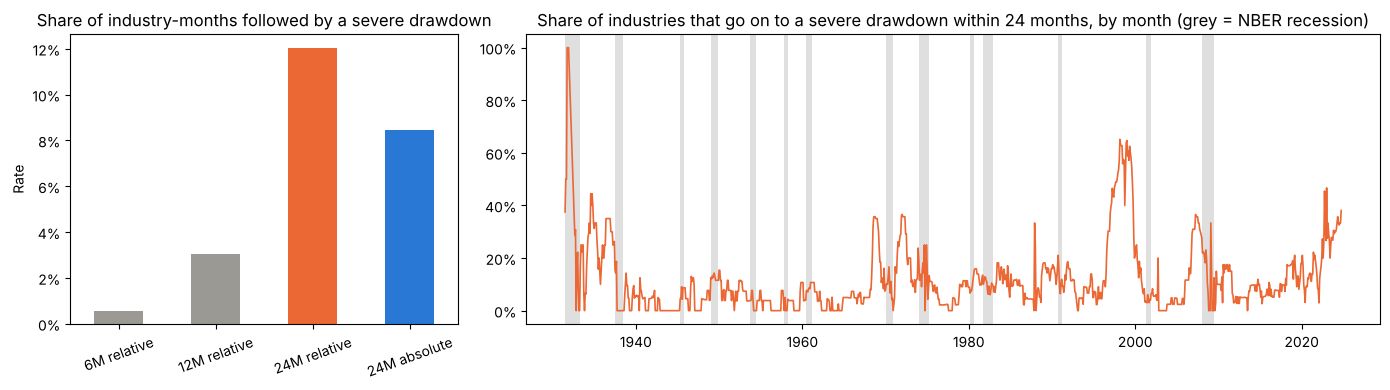

6M relative     0.006
12M relative    0.031
24M relative    0.120
24M absolute    0.084

Monthly rate: median 8.1%, 90th percentile 29.3%, maximum 100.0% (1931-09); months with a rate of 0: 14%


In [17]:
# 4.1 How common is a severe drawdown, and how does its frequency move over time?
TARGET = f"Crash_{MAIN_H}"
eda = panel[~panel["Masked"] & panel[TARGET].notna()]
rate_m = eda.groupby(level="Date")[TARGET].mean()
fig, ax = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1, 2.2]})
base = pd.Series({f"{H}M relative": panel.loc[~panel["Masked"], f"Crash_{H}"].mean() for H in H_LIST} |
                 {f"{MAIN_H}M absolute": panel.loc[~panel["Masked"], f"CrashAbs_{MAIN_H}"].mean()})
base.plot(kind="bar", ax=ax[0], color=["#9a9994", "#9a9994", "#eb6834", "#2a78d6"], rot=20)
ax[0].set(title="Share of industry-months followed by a severe drawdown", ylabel="Rate")
ax[0].yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
ax[1].plot(rate_m, color="#eb6834", lw=1.2)
rec = usrec.reindex(rate_m.index).ffill().eq(1)
ax[1].fill_between(rate_m.index, 0, 1, where=rec.values, color="gray", alpha=0.25, lw=0, transform=ax[1].get_xaxis_transform())
ax[1].set(title=f"Share of industries that go on to a severe drawdown within {MAIN_H} months, by month (grey = NBER recession)")
ax[1].yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
plt.tight_layout(); plt.show()
print(base.round(3).to_string())
print(f"\nMonthly rate: median {rate_m.median():.1%}, 90th percentile {rate_m.quantile(0.9):.1%}, maximum {rate_m.max():.1%} ({rate_m.idxmax():%Y-%m}); "
      f"months with a rate of 0: {(rate_m == 0).mean():.0%}")

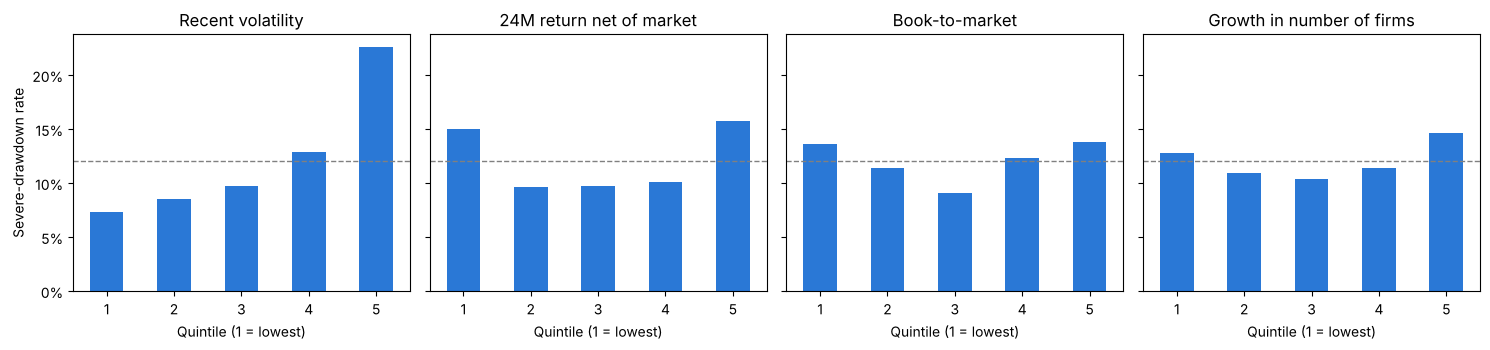

,Recent volatility,24M return net of market,Book-to-market,Growth in number of firms
1,0.073,0.150,0.136,0.128
2,0.085,0.096,0.114,0.110
3,0.097,0.098,0.091,0.104
4,0.129,0.101,0.124,0.114
5,0.226,0.158,0.138,0.147


In [18]:
# 4.2 Does the rate differ by volatility, past return, valuation and firm entry? (quintiles of the cross-sectional rank)
EDA_FEATS = {"Vol6_R": "Recent volatility", "Net24_R": "24M return net of market", "BM_R": "Book-to-market", "Firms_Chg24_R": "Growth in number of firms"}
by_q = pd.DataFrame({name: eda.groupby(np.ceil(eda[f] * 5).clip(1, 5).astype(int))[TARGET].mean() for f, name in EDA_FEATS.items()})
fig, ax = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
for a, col in zip(ax, by_q):
    by_q[col].plot(kind="bar", ax=a, color="#2a78d6", rot=0)
    a.axhline(eda[TARGET].mean(), color="gray", ls="--", lw=1)
    a.set(title=col, xlabel="Quintile (1 = lowest)")
    a.yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
ax[0].set_ylabel("Severe-drawdown rate")
plt.tight_layout(); plt.show()
by_q.round(3)

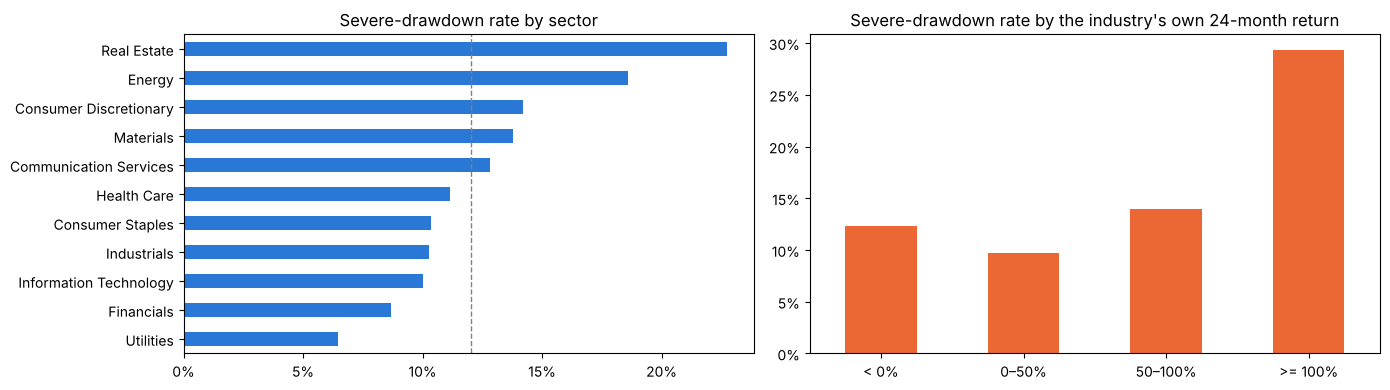

Industry,Utilities,Financials,Information Technology,Industrials,Consumer Staples,Health Care,Communication Services,Materials,Consumer Discretionary,Energy,Real Estate
Rate,0.065,0.087,0.1,0.103,0.103,0.111,0.128,0.138,0.142,0.186,0.227


R24,< 0%,0–50%,50–100%,>= 100%
Rate,0.124,0.098,0.14,0.294
Industry-months,5694.000,20404.000,7627.00,1703.000


In [19]:
# 4.3 Rate by sector, and by the size of the 24-month return
sector_rate = eda.groupby(eda.index.get_level_values("Industry").map(SECTOR_OF))[TARGET].mean().sort_values()
r24_bucket = pd.cut(eda["R24"], [-np.inf, 0, 0.5, 1.0, np.inf], labels=["< 0%", "0–50%", "50–100%", ">= 100%"])
r24_rate = eda.groupby(r24_bucket, observed=False)[TARGET].agg(["mean", "size"])
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sector_rate.plot(kind="barh", ax=ax[0], color="#2a78d6")
ax[0].axvline(eda[TARGET].mean(), color="gray", ls="--", lw=1)
ax[0].set(title="Severe-drawdown rate by sector", ylabel="")
ax[0].xaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
r24_rate["mean"].plot(kind="bar", ax=ax[1], color="#eb6834", rot=0)
ax[1].set(title="Severe-drawdown rate by the industry's own 24-month return", xlabel="")
ax[1].yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
plt.tight_layout(); plt.show()
display(sector_rate.round(3).to_frame("Rate").T, r24_rate.round(3).rename(columns={"mean": "Rate", "size": "Industry-months"}).T)

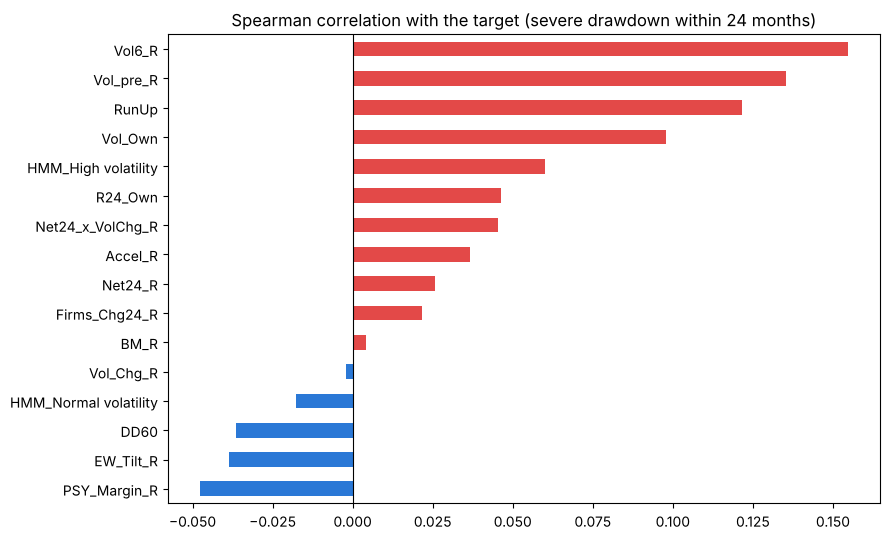

,PSY_Margin_R,EW_Tilt_R,DD60,HMM_Normal volatility,Vol_Chg_R,BM_R,Firms_Chg24_R,Net24_R,Accel_R,Net24_x_VolChg_R,R24_Own,HMM_High volatility,Vol_Own,RunUp,Vol_pre_R,Vol6_R
Spearman,-0.048,-0.039,-0.036,-0.018,-0.002,0.004,0.022,0.026,0.037,0.045,0.046,0.06,0.098,0.121,0.135,0.155


In [20]:
# 4.4 Rank correlation of every candidate feature with the target
corr = eda[FEATS_MAIN + FEATS_BUBBLE + FEATS_OWN + [f"HMM_{r}" for r in REGIMES[1:]]].corrwith(eda[TARGET], method="spearman").sort_values()
ax = corr.plot(kind="barh", figsize=(9, 5.5), color=["#e34948" if v > 0 else "#2a78d6" for v in corr])
ax.axvline(0, color="black", lw=0.8)
ax.set(title="Spearman correlation with the target (severe drawdown within 24 months)")
plt.tight_layout(); plt.show()
corr.round(3).to_frame("Spearman").T

### What the EDA tells us

- **The target is a minority class.** About 12% of early-warning industry-months are followed by a relative drawdown of at least 30% within 24 months (3% within 12 months, under 1% within 6). Plain accuracy would be misleading: a model that always says "no" is right 88% of the time. This is why the metric is a ranking score (AUC), and why the benchmark is a base rate, not a majority class.
- **Volatility is the strongest single signal.** The rate rises steadily from 7.3% in the lowest quintile of recent volatility to 22.6% in the highest, a factor of three. No other feature shows such a clean gradient, which already hints at the result of H2.
- **Past return is U-shaped, not linear.** Industries in the lowest and the highest quintile of market-adjusted 24-month return both have a rate of about 15–16%, against about 10% in the middle. Losers and winners are both at risk; a linear model cannot see this, a tree model can.
- **Very large run-ups stand out.** When the industry's own 24-month return is 100% or more, the rate is 29.4%, against 10–14% otherwise. Only 1,703 of about 35,000 rows are in that group.
- **Sectors differ by a factor of more than three:** from 6.5% for Utilities to 18.6% for Energy and 22.7% for Real Estate. This is largely the same volatility effect seen through another lens.
- **Every correlation with the target is weak** (|Spearman| ≤ 0.16). The strongest are the two volatility ranks (+0.155 and +0.135) and the run-up flag (+0.121). The GSADF signal strength is slightly *negative* (−0.048): industries with strongly "explosive" prices were, if anything, a little less likely to suffer a relative drawdown. No single feature is a strong predictor, so any useful model must combine them.

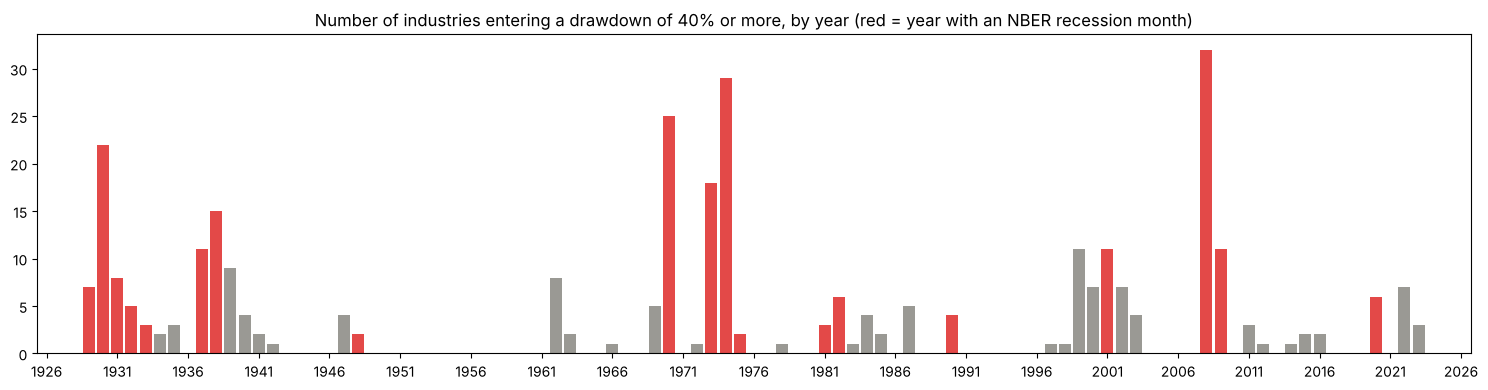

Years with the most onsets: 2008 (32), 1974 (29), 1970 (25), 1930 (22), 1973 (18), 1938 (15) | share of onsets in recession years: 68% (recession years are 31% of all years)


In [21]:
# 4.5 Severe drawdowns come in waves: industries that start an absolute drawdown of 40% or more, by year
dd24 = price / price.rolling(24, min_periods=1).max() - 1
onset = (dd24 <= -ABS_DD) & ~(dd24.shift(1) <= -ABS_DD) & eligible
per_year = onset.groupby(onset.index.year).sum().sum(axis=1)
rec_year = usrec.groupby(usrec.index.year).max().reindex(per_year.index).fillna(0)
ax = per_year.plot(kind="bar", figsize=(15, 4), color=["#e34948" if r else "#9a9994" for r in rec_year], width=0.85)
ax.set(title="Number of industries entering a drawdown of 40% or more, by year (red = year with an NBER recession month)", xlabel="")
ax.set_xticks(range(0, len(per_year), 5)); ax.set_xticklabels(per_year.index[::5], rotation=0)
plt.tight_layout(); plt.show()
top = per_year.nlargest(6)
print("Years with the most onsets:", ", ".join(f"{y} ({int(n)})" for y, n in top.items()),
      f"| share of onsets in recession years: {per_year[rec_year == 1].sum() / per_year.sum():.0%} (recession years are {rec_year.mean():.0%} of all years)")

**Reading this chart.** Severe drawdowns are not spread evenly through time; they arrive in **waves**: 1930, 1937–38, 1970, 1973–74, 2000–02 and 2008, when 32 of 48 industries entered a 40% drawdown in one year. 68% of all onsets fall in years with a recession, although such years are only 31% of the sample. Two consequences follow. First, observations are far from independent, so every interval in this notebook resamples whole blocks of months instead of single rows. Second, a fall that hits most industries at once is a *market* event, not information about one industry; this is the reason the target is measured **relative to the market**, and it previews §7: knowing *which* industry is risky turns out to be feasible, knowing *when* the wave comes does not.

## 5. Modeling

**Feature representation.** Eight features in three groups, all cross-sectional ranks except the run-up flag:
- **Price run-up:** strict run-up flag, 24-month return net of the market, price acceleration.
- **Volatility:** volatility before the run-up, recent volatility, rise in volatility.
- **Issuance / valuation:** growth in the number of firms, book-to-market.

**Algorithms compared** (a ladder from simple to flexible):
1. **Base rate** — the same probability for every industry; no ranking skill by construction.
2. **Logit-Vol** — a logistic regression on the two volatility ranks only. This is the traditional risk measure, and the benchmark for H2.
3. **Logit** — a logistic regression on all eight features.
4. **Random Forest** — a non-linear ensemble on the same eight features (200 shallow trees, at least 300 rows per leaf).

**Validation design (walk-forward).** For each test year *Y* from 1960, every model is fitted on rows dated up to 31 December of *Y−1* and scores year *Y*.
- **Embargo:** a training row is used only if its 24-month outcome was already known at the fit date.
- **No leakage through preprocessing:** the winsoriser and the scaler sit inside a `Pipeline`, so they are fitted on the training rows only.
- **Time decay:** the half-life of the training weights is chosen on 1945–1959 only, before the test period starts, and then locked.

In [22]:
# 5.1 Model definitions (Pipeline: winsorise -> scale -> classifier)
class Winsorizer(BaseEstimator, TransformerMixin):
    """Clip continuous features to training-set quantiles; 0/1 flags are left unchanged."""
    def __init__(self, lower=WINSOR[0], upper=WINSOR[1]):
        self.lower, self.upper = lower, upper
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.lo_, self.hi_ = np.quantile(X, [self.lower, self.upper], axis=0)
        flag = np.array([np.unique(c).size <= 2 for c in X.T])
        self.lo_[flag], self.hi_[flag] = -np.inf, np.inf
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)

def make_model(kind):
    if kind == "rf":
        clf = RandomForestClassifier(n_estimators=200, max_depth=4, min_samples_leaf=300, max_samples=0.5,
                                     n_jobs=-1, random_state=SEED)
        return Pipeline([("clip", Winsorizer()), ("clf", clf)])
    return Pipeline([("clip", Winsorizer()), ("scale", StandardScaler()), ("clf", LogisticRegression(C=1.0, max_iter=3000))])

MODEL_SPECS = {VOL_MODEL:   ("logit", FEATS_VOL),
               BENCH_MODEL: ("logit", FEATS_MAIN),
               MAIN_MODEL:  ("rf",    FEATS_MAIN)}
MODELS = list(MODEL_SPECS)

In [23]:
# 5.2 Walk-forward engine: refit every year, embargo on the label, time-decay weights
CARRY = ["Masked", "MCap", "RunUp", "PSY_Bubble", "R24", "Net24_R"]     # columns copied to the prediction table

def walk_forward(label, specs, H, rows=None, half_life=None, keep_years=(), years=None):
    """Returns (pred, fitted, insample): out-of-sample predictions, models of `keep_years`, in-sample AUC per fit."""
    data = panel if rows is None else rows
    half_life = HALF_LIFE if half_life is None else half_life
    lab = data[data[label].notna() & ~data["Masked"]]
    lab_dates = lab.index.get_level_values("Date")
    preds, fitted, insample = [], {}, []
    for year in (years or range(FIRST_TEST_YEAR, data["Year"].max() + 1)):
        fit_date = pd.Timestamp(f"{year - 1}-12-31")
        train = lab[lab_dates <= fit_date - pd.DateOffset(months=H)]            # embargo
        test = data[data["Year"] == year]
        if test.empty or len(train) < MIN_TRAIN or train[label].nunique() < 2:
            continue
        age = np.asarray((fit_date - train.index.get_level_values("Date")).days) / 365.25
        w = 0.5 ** (age / half_life)                                            # half_life = inf gives equal weights
        y_tr = train[label].astype(int).values
        out = test[[label] + CARRY].rename(columns={label: "y"})
        out["Base rate"] = np.average(y_tr, weights=w)
        for name, (kind, feats) in specs.items():
            ok_tr, ok_te = train[feats].notna().all(axis=1).values, test[feats].notna().all(axis=1).values
            out[name] = np.nan
            if ok_tr.sum() < MIN_TRAIN or len(set(y_tr[ok_tr])) < 2 or not ok_te.any():
                continue
            model = make_model(kind).fit(train.loc[ok_tr, feats], y_tr[ok_tr], clf__sample_weight=w[ok_tr])
            out.loc[ok_te, name] = model.predict_proba(test.loc[ok_te, feats])[:, 1]
            p_in, y_in, yr_in = model.predict_proba(train.loc[ok_tr, feats])[:, 1], y_tr[ok_tr], train["Year"].values[ok_tr]
            insample.append({"Year": year, "Model": name,                        # AUC inside each training year, averaged
                             "AUC in-sample": np.mean([roc_auc_score(y_in[yr_in == k], p_in[yr_in == k])
                                                       for k in np.unique(yr_in) if 0 < y_in[yr_in == k].mean() < 1])})
            if year in keep_years:
                fitted[(year, name)] = model
        preds.append(out)
    return pd.concat(preds).sort_index(), fitted, pd.DataFrame(insample)

In [24]:
# 5.3 Choose the half-life on 1945-1959 only (nested validation), then lock it
valid_rows = []
for hl in HALF_LIFE_GRID:
    v, _, _ = walk_forward(f"Crash_{MAIN_H}", {m: MODEL_SPECS[m] for m in [BENCH_MODEL, MAIN_MODEL]}, MAIN_H, half_life=hl, years=VALID_YEARS)
    v = v[~v["Masked"] & v["y"].notna()]
    valid_rows.append({"Half-life (years)": hl, "Rows": len(v), "Crash rate": v["y"].mean(),
                       **{f"AUC {m}": roc_auc_score(v["y"], v[m]) for m in [MAIN_MODEL, BENCH_MODEL]},
                       **{f"Brier {m}": ((v[m] - v["y"]) ** 2).mean() for m in [MAIN_MODEL, BENCH_MODEL]}})
half_life_table = pd.DataFrame(valid_rows).set_index("Half-life (years)")
HALF_LIFE = half_life_table[f"AUC {MAIN_MODEL}"].idxmax()
half_life_table["Chosen"] = half_life_table.index == HALF_LIFE
half_life_table.round(4)

,Rows,Crash rate,AUC RandomForest,AUC Logit,Brier RandomForest,Brier Logit,Chosen
Half-life (years),,,,,,,
10.0,4382,0.0504,0.5623,0.5416,0.0489,0.0502,False
20.0,4382,0.0504,0.5973,0.5552,0.0493,0.0510,False
40.0,4382,0.0504,0.6126,0.5612,0.0496,0.0516,False
inf,4382,0.0504,0.6147,0.5663,0.0503,0.0524,True


In [25]:
# 5.4 Run every model at every horizon (and once on the absolute target, for comparison)
PRED, INSAMPLE = {}, {}
for H in H_LIST:
    PRED[H], fitted, INSAMPLE[H] = walk_forward(f"Crash_{H}", MODEL_SPECS, H, keep_years=[*EXPLAIN_YEARS.values(), panel["Year"].max()])
    if H == MAIN_H:
        FITTED = fitted
PRED_ABS, _, _ = walk_forward(f"CrashAbs_{MAIN_H}", MODEL_SPECS, MAIN_H)
d = PRED[MAIN_H].index.get_level_values("Date")
print(f"Out-of-sample predictions: {d.min():%Y-%m} to {d.max():%Y-%m}, {len(PRED[MAIN_H]):,} industry-months, "
      f"{int(PRED[MAIN_H]['y'].notna().sum()):,} with a known 24-month outcome")

Out-of-sample predictions: 1960-01 to 2026-09, 33,360 industry-months, 32,384 with a known 24-month outcome


In [26]:
# 5.5 Metrics (XS-AUC, Time-AUC, AUC, BSS) and month-block bootstrap intervals
def block_positions(n, seed=SEED):
    rng = np.random.default_rng(seed)                               # same seed -> comparisons between models are paired
    for _ in range(N_BOOT):
        starts = rng.integers(0, n - BLOCK + 1, size=int(np.ceil(n / BLOCK)))
        yield np.concatenate([np.arange(s, s + BLOCK) for s in starts])[:n]

def early_warning(pred):
    return pred[~pred["Masked"] & pred["y"].notna()]

def xs_auc(df, col):
    return pd.Series({d: roc_auc_score(g["y"], g[col]) for d, g in df.groupby(level="Date")
                      if g["y"].nunique() == 2 and g[col].nunique() > 1}, dtype=float)

def bss(y, p, base):
    return 1 - np.mean((p - y) ** 2) / np.mean((base - y) ** 2)

def metric_draws(df, col):
    """Point estimate (row 0) and bootstrap draws of [XS-AUC, Time-AUC, AUC, PR lift, BSS] for one model column."""
    y, p, base = df["y"].values.astype(int), df[col].values, df["Base rate"].values
    p_time = df.groupby(level="Date")[col].transform("mean").values
    codes, months = pd.factorize(df.index.get_level_values("Date"))
    rows_of = [np.flatnonzero(codes == k) for k in range(len(months))]
    xs = xs_auc(df, col).reindex(months).values
    def calc(pos):
        ix = np.concatenate([rows_of[k] for k in pos])
        if y[ix].min() == y[ix].max():
            return [np.nan] * 5
        x = xs[pos]
        return [np.nanmean(x) if np.isfinite(x).any() else np.nan, roc_auc_score(y[ix], p_time[ix]),
                roc_auc_score(y[ix], p[ix]), average_precision_score(y[ix], p[ix]) / y[ix].mean(), bss(y[ix], p[ix], base[ix])]
    return np.array([calc(np.arange(len(months)))] + [calc(pos) for pos in block_positions(len(months))])

METRICS = ["XS-AUC", "Time-AUC", "AUC", "PR lift", "BSS"]

def evaluate(df, models):
    df = df.dropna(subset=["y", "Base rate"] + models).sort_index()
    out = {}
    for m in models:
        d = metric_draws(df, m)
        lo, hi = np.nanpercentile(d[1:], [2.5, 97.5], axis=0)
        out[m] = {"N": len(df), "Crash rate": df["y"].mean(), **dict(zip(METRICS, d[0])),
                  **{f"{k} lo": v for k, v in zip(METRICS, lo)}, **{f"{k} hi": v for k, v in zip(METRICS, hi)}}
    return pd.DataFrame(out).T.astype({"N": int})

def paired_diff(df, a, b):
    """Bootstrap difference a - b on identical rows and months; p = two-sided bootstrap p-value."""
    df = df.dropna(subset=["y", "Base rate", a, b]).sort_index()
    d = metric_draws(df, a) - metric_draws(df, b)
    row = {}
    for k, name in enumerate(METRICS):
        if name == "PR lift":
            continue
        draws = d[1:, k][np.isfinite(d[1:, k])]
        row.update({f"Δ{name}": d[0, k], f"Δ{name} lo": np.percentile(draws, 2.5), f"Δ{name} hi": np.percentile(draws, 97.5),
                    f"p {name}": max(2 * min((draws <= 0).mean(), (draws >= 0).mean()), 1 / N_BOOT)})
    return row

def top_k_alert(pred, model, k=ALERT_K):
    p = pred[model].where(~pred["Masked"])
    return p.groupby(level="Date").rank(ascending=False, method="first") <= k

EW = {H: early_warning(PRED[H]) for H in H_LIST}
EW_ABS = early_warning(PRED_ABS)

def month_boot(df, stat):
    """Point estimate and month-block bootstrap interval of stat(row_positions); df must be sorted by date."""
    codes, months = pd.factorize(df.index.get_level_values("Date"))
    rows_of = [np.flatnonzero(codes == k) for k in range(len(months))]
    point = np.asarray(stat(np.arange(len(df))), dtype=float)
    draws = np.array([stat(np.concatenate([rows_of[k] for k in pos])) for pos in block_positions(len(months))], dtype=float)
    return point, np.nanpercentile(draws, 2.5, axis=0), np.nanpercentile(draws, 97.5, axis=0), draws

def risk_level(pred, model=MAIN_MODEL):
    """Quartile of the monthly ranking among industries that are not already falling."""
    rank = pred[model].where(~pred["Masked"]).groupby(level="Date").rank(pct=True)
    return pd.cut(rank, [0, 0.25, 0.5, 0.75, 1.0], labels=LEVELS), rank

In [27]:
# 5.6 Model comparison at every horizon
results = {H: evaluate(EW[H], ["Base rate"] + MODELS) for H in H_LIST}
scorecard = pd.concat(results, names=["Horizon (months)", "Model"])
scorecard[["N", "Crash rate", "XS-AUC", "XS-AUC lo", "XS-AUC hi", "Time-AUC", "AUC", "BSS", "BSS lo", "BSS hi"]].rename(
    columns={"Crash rate": "Severe-drawdown rate"}).round(3)

N  Severe-drawdown rate  XS-AUC  XS-AUC lo  XS-AUC hi  Time-AUC    AUC    BSS  BSS lo  BSS hi
Horizon (months) Model                                                                                                          
6                Base rate     29212                 0.007     NaN        NaN        NaN     0.602  0.602  0.000   0.000   0.000
                 Logit-Vol     29212                 0.007   0.841      0.780      0.928     0.612  0.763  0.013   0.007   0.020
                 Logit         29212                 0.007   0.819      0.758      0.894     0.585  0.749  0.016   0.007   0.026
                 RandomForest  29212                 0.007   0.831      0.776      0.914     0.610  0.745  0.011   0.006   0.019
12               Base rate     28983                 0.035     NaN        NaN        NaN     0.561  0.561  0.000   0.000   0.000
                 Logit-Vol     28983                 0.035   0.783      0.738      0.847     0.563  0.666  0.022   0.011   0.036
                 Logit         28983                 0.035   0.754      0.702      0.824     0.594  0.657  0.030   0.012   0.055
                 RandomForest  28983                 0.035   0.782      0.736      0.841     0.568  0.671  0.023   0.011   0.039
24               Base rate     28502                 0.131     NaN        NaN        NaN     0.499  0.499  0.000   0.000   0.000
                 Logit-Vol     28502                 0.131   0.703      0.666      0.742     0.502  0.631  0.035   0.021   0.060
                 Logit         28502                 0.131   0.678      0.645      0.724     0.526  0.624  0.036   0.016   0.063
                 RandomForest  28502                 0.131   0.710      0.682      0.742     0.516  0.628  0.036   0.022   0.057

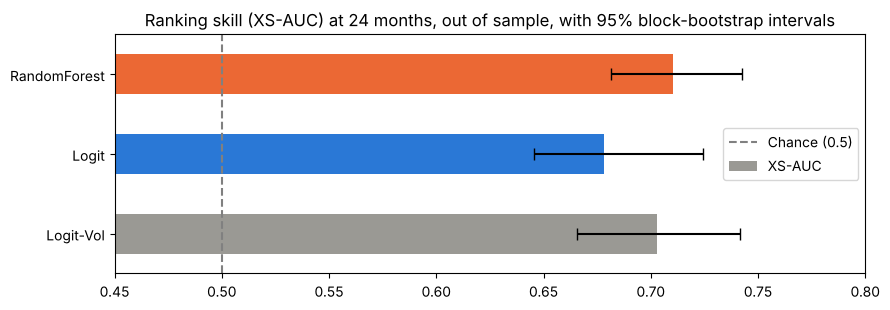

In [28]:
# Visual comparison of ranking skill at 24 months against chance (0.5)
r = results[MAIN_H].loc[MODELS]
ax = r["XS-AUC"].plot(kind="barh", figsize=(9, 3.2), color=[MODEL_COLORS[m] for m in MODELS],
                      xerr=[r["XS-AUC"] - r["XS-AUC lo"], r["XS-AUC hi"] - r["XS-AUC"]], capsize=4)
ax.axvline(0.5, color="gray", ls="--", label="Chance (0.5)")
ax.set(title=f"Ranking skill (XS-AUC) at {MAIN_H} months, out of sample, with 95% block-bootstrap intervals", xlim=(0.45, 0.8))
ax.legend(); plt.tight_layout(); plt.show()

### Reading the model comparison

- **Every model ranks industries far better than chance.** At 24 months the XS-AUC is 0.703 for the volatility-only Logit, 0.678 for the full Logit and **0.710 for the Random Forest**, with intervals well above 0.5. **H1 is supported.**
- **The Random Forest does not beat the volatility benchmark.** 0.710 against 0.703 is a difference of 0.007, far inside the bootstrap intervals. The full Logit is even slightly below the benchmark. **H2 is not supported** at this stage; §8.2 tests it more carefully.
- **There is no timing skill.** Time-AUC is about 0.5 for every model at 24 months (0.516 for the Random Forest): the models say *which* industry, not *when*.
- **The probabilities are slightly better than the base rate.** The Brier skill score is small but its interval is above 0 (0.036 for the Random Forest), so the scores carry some information about the level of risk, not only the order.
- **The pattern is the same at 6 and 12 months**, with higher XS-AUC at short horizons because severe drawdowns within 6 months are rare and concentrated in the most volatile industries.

We carry the **Random Forest** forward as the main model because the project plan named it and it handles interactions, but the comparison above already says that most of its skill is available from volatility alone.

## 6. Evaluation

We evaluate the main model in the form a user would see it: four **risk levels**, the pooled ROC curve, and the features the model relies on.

In [29]:
# 6.1 Four risk levels = quartiles of the monthly ranking (fixed in advance), and what followed each level
LV = PRED[MAIN_H].copy()
LV["Level"], LV["Rank"] = risk_level(LV)
LV["Level (vol-only)"], _ = risk_level(LV, VOL_MODEL)
T = LV[LV["y"].notna() & LV["Level"].notna()].sort_index()                     # rated rows with a known outcome
y, code = T["y"].values, T["Level"].cat.codes.values
by_level = lambda ix: [y[ix][code[ix] == j].mean() for j in range(4)]
pt, lo, hi, draws = month_boot(T, by_level)
level_table = pd.DataFrame({"Industry-months": np.bincount(code, minlength=4), "Severe drawdowns": np.bincount(code, weights=y, minlength=4).astype(int),
                            "Rate 24M": pt, "95% lo": lo, "95% hi": hi, "x overall rate": pt / y.mean()}, index=LEVELS)
for H in (6, 12):
    q = PRED[H].assign(Level=risk_level(PRED[H])[0])
    level_table[f"Rate {H}M"] = q[q["y"].notna()].groupby("Level", observed=False)["y"].mean()
LEVEL_RATE = level_table[["Rate 24M", "95% lo", "95% hi", "Industry-months"]]
t_dates = T.index.get_level_values("Date")
level_facts = pd.Series({"Assessment months with a known outcome": f"{t_dates.min():%Y-%m} to {t_dates.max():%Y-%m}",
                         "Overall severe-drawdown rate (24M)": round(y.mean(), 3),
                         "Bootstrap draws in which the rate rises at every step, Low to High": f"{(np.diff(draws, axis=1) > 0).all(axis=1).mean():.0%}"},
                        name="Value", dtype=object).to_frame()
display(level_table.round(3), level_facts)

,Industry-months,Severe drawdowns,Rate 24M,95% lo,95% hi,x overall rate,Rate 6M,Rate 12M
Low,6861,503,0.073,0.030,0.109,0.559,0.002,0.017
Normal,7201,713,0.099,0.060,0.137,0.755,0.003,0.023
Elevated,7038,888,0.126,0.087,0.168,0.962,0.005,0.028
High,7402,1636,0.221,0.177,0.262,1.684,0.016,0.071


,Value
Assessment months with a known outcome,1960-01 to 2024-09
Overall severe-drawdown rate (24M),0.131
"Bootstrap draws in which the rate rises at every step, Low to High",100%


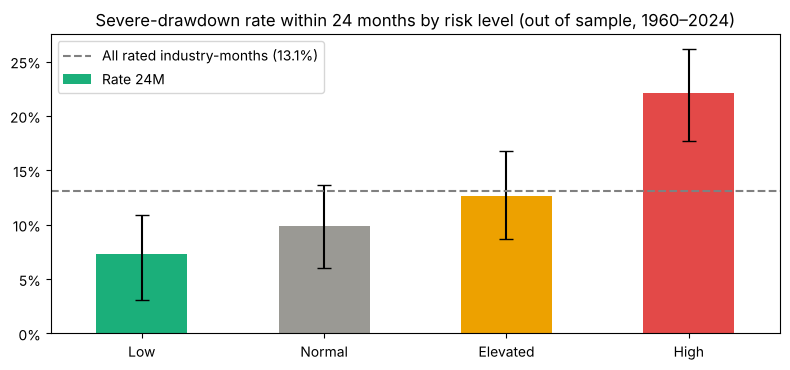

In [30]:
# Risk levels: share of industry-months followed by a severe drawdown, with 95% block-bootstrap intervals
ax = level_table["Rate 24M"].plot(kind="bar", figsize=(8, 3.8), color=["#1baf7a", "#9a9994", "#eda100", "#e34948"], rot=0,
                                  yerr=[level_table["Rate 24M"] - level_table["95% lo"], level_table["95% hi"] - level_table["Rate 24M"]], capsize=5)
ax.axhline(y.mean(), color="gray", ls="--", label=f"All rated industry-months ({y.mean():.1%})")
ax.set(title=f"Severe-drawdown rate within {MAIN_H} months by risk level (out of sample, 1960–2024)")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
ax.legend(); plt.tight_layout(); plt.show()

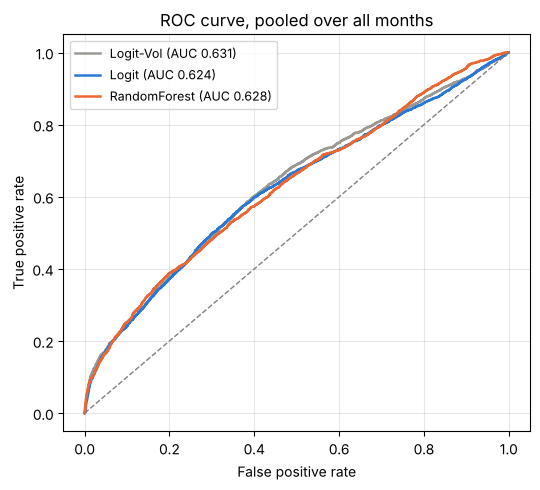

In [31]:
# 6.2 Pooled ROC curve at 24 months
ew = EW[MAIN_H].dropna(subset=["y"] + MODELS)
fig, ax = plt.subplots(figsize=(5.5, 5))
for m in MODELS:
    fpr, tpr, _ = roc_curve(ew["y"], ew[m])
    ax.plot(fpr, tpr, color=MODEL_COLORS[m], lw=1.8, label=f"{m} (AUC {roc_auc_score(ew['y'], ew[m]):.3f})")
ax.plot([0, 1], [0, 1], color="gray", ls="--", lw=1)
ax.set(title="ROC curve, pooled over all months", xlabel="False positive rate", ylabel="True positive rate")
ax.legend(fontsize=9); ax.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

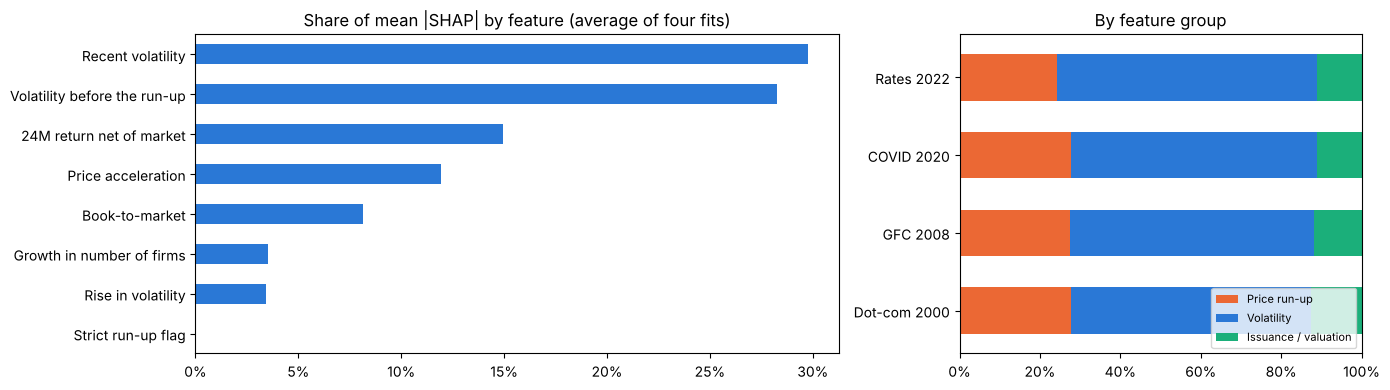

,Dot-com 2000,GFC 2008,COVID 2020,Rates 2022
Price run-up,0.278,0.276,0.278,0.243
Volatility,0.597,0.605,0.611,0.646
Issuance / valuation,0.125,0.119,0.112,0.111


In [32]:
# 6.3 What does the Random Forest rely on? SHAP importance by feature and by feature group, for models fitted before four stress periods
FEAT_LABEL = {"RunUp": "Strict run-up flag", "Net24_R": "24M return net of market", "Accel_R": "Price acceleration", "Vol_pre_R": "Volatility before the run-up",
              "Vol6_R": "Recent volatility", "Vol_Chg_R": "Rise in volatility", "Firms_Chg24_R": "Growth in number of firms", "BM_R": "Book-to-market"}

def shap_values(model, X):
    Xt = model["clip"].transform(X)
    expl = shap.TreeExplainer(model["clf"])
    sv = expl.shap_values(Xt)
    sv = sv[1] if isinstance(sv, list) else (sv[:, :, 1] if np.ndim(sv) == 3 else sv)      # class 1 = severe drawdown
    gap = np.abs(np.atleast_1d(expl.expected_value)[-1] + sv.sum(axis=1) - model["clf"].predict_proba(Xt)[:, 1]).max()
    assert gap < 1e-3, "SHAP additivity failed"
    return pd.DataFrame(sv, index=X.index, columns=X.columns)

imp = {}
for crisis, year in EXPLAIN_YEARS.items():
    rows = panel[(panel["Year"] == year) & ~panel["Masked"]]
    imp[crisis] = shap_values(FITTED[(year, MAIN_MODEL)], rows[FEATS_MAIN]).abs().mean()
imp = pd.DataFrame(imp)
imp = imp / imp.sum()
shap_group = pd.DataFrame({g: imp.loc[f].sum() for g, f in FEAT_GROUP.items()}).T
fig, ax = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1.6, 1]})
imp.rename(index=FEAT_LABEL).mean(axis=1).sort_values().plot(kind="barh", ax=ax[0], color="#2a78d6")
ax[0].set(title="Share of mean |SHAP| by feature (average of four fits)")
shap_group.T.plot(kind="barh", stacked=True, ax=ax[1], color=["#eb6834", "#2a78d6", "#1baf7a"], width=0.6)
ax[1].set(title="By feature group", xlim=(0, 1)); ax[1].legend(fontsize=8, loc="lower right")
for a in ax: a.xaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
plt.tight_layout(); plt.show()
shap_group.round(3)

### What the evaluation reveals

- **The four levels separate risk, in the right order.** 7.3% of Low-level industry-months were followed by a severe drawdown, 9.9% of Normal, 12.6% of Elevated and **22.1% of High**. The rate rises at every step in 100% of the bootstrap draws, and the same ordering appears at 6 and 12 months.
- **The High level is where the information is.** Low, Normal and Elevated are close to each other (7–13%); High is about 1.7 times the overall rate of 13.1%. The ranking is most useful for flagging the riskiest quarter of industries, less so for telling the other three quarters apart.
- **A level is a relative statement.** A quarter of the rated industries is always "High", even in a calm market, and almost four out of five High-level months were *not* followed by a severe drawdown. The level says "riskier than the others", not "will fall".
- **The pooled ROC curves of the three models lie almost on top of each other** (AUC about 0.63). Pooled AUC is lower than XS-AUC because it also asks for timing, which none of the models has.
- **Volatility is what the model uses.** The volatility group holds about 60% of the SHAP importance in all four fits, price run-up about 27%, issuance and valuation about 12%. The strict run-up flag contributes almost nothing because it is switched on in only 0.8% of rows. SHAP describes the model, not the causes of a drawdown.
- **Bottom line:** a real, stable ranking signal, built mostly on volatility. That is an honest result; §7 asks whether anything can be added to it.

## 7. Improving the Model

The §6 model ranks well but leans on volatility and has no timing skill. The EDA suggested two things worth trying: severe drawdowns come in **waves** (§4.5), so market-wide information might help, and the largest price run-ups carry the highest rates (§4.3), so signals that describe a bubble might help. We test four ideas.

**Candidate improvements**
- **Bubble signals** — the strength of the GSADF signal, a tilt towards small firms (equal- minus value-weighted return), and volatility that rises during a run-up.
- **Market regime** — the HMM probabilities of the Normal- and High-volatility regimes, plus an interaction with the run-up.
- **Own-history features** — volatility and return measured against the industry's own last 10 years, and the distance from its 5-year high. Cross-sectional ranks remove the market-wide level of risk; these put it back.
- **Other settings** — a different target (absolute 40%, relative 20% or 40%), features without ranks, and other half-lives.

> **⚠️ Leakage control.** Every added feature uses data up to month *t* only (the GSADF and HMM signals passed truncation tests in §3). Each variant is run through the **same walk-forward**, on **identical rows**, and compared with the main feature set with a paired block bootstrap. Because many comparisons are made, p-values are adjusted with the Benjamini–Hochberg false discovery rate.

**Honest framing:** if none of these helps, the conclusion is that the ranking is a volatility ranking with a small extra contribution, and that is what we report.

In [33]:
# 7.1 Ablation: add each feature group to the main set and rerun the same walk-forward on identical rows
HMM_FEATS = [f"HMM_{r}" for r in REGIMES[1:]]
ABL_SETS = {"Main": FEATS_MAIN, "Main + bubble signals": FEATS_MAIN + FEATS_BUBBLE,
            "Main + HMM regime": FEATS_MAIN + HMM_FEATS, "Main + own history": FEATS_MAIN + FEATS_OWN,
            "Main + all": FEATS_MAIN + FEATS_BUBBLE + HMM_FEATS + FEATS_OWN}
ABL_SPECS = {f"{fam} | {name}": (kind, feats + (["Net24_x_HighVol"] if kind == "logit" and HMM_FEATS[0] in feats else []))
             for kind, fam in [("logit", "Logit"), ("rf", "RF")] for name, feats in ABL_SETS.items()}   # a Logit needs the interaction spelled out
abl_rows = panel.dropna(subset=FEATS_BUBBLE + HMM_FEATS + FEATS_OWN)             # same rows for every variant
ABL, _, _ = walk_forward(f"Crash_{MAIN_H}", ABL_SPECS, MAIN_H, rows=abl_rows)

In [34]:
# 7.2 Paired differences against the main feature set (95% block-bootstrap intervals, FDR-adjusted)
ew_abl = early_warning(ABL)
rows = []
for fam in ["Logit", "RF"]:
    for name in list(ABL_SETS)[1:]:
        d = paired_diff(ew_abl, f"{fam} | {name}", f"{fam} | Main")
        rows.append({"Model": fam, "Variant vs Main": name, **d})
abl_tests = pd.DataFrame(rows).set_index(["Model", "Variant vs Main"])
p_cols = ["p XS-AUC", "p Time-AUC", "p AUC", "p BSS"]
p_adj = multipletests(abl_tests[p_cols].values.ravel(), alpha=0.10, method="fdr_bh")[1].reshape(abl_tests[p_cols].shape)
abl_tests["Significant (FDR 10%)"] = [", ".join(c[2:] for c, q in zip(p_cols, row) if q < 0.10) or "none" for row in p_adj]
abl_scores = evaluate(ew_abl, list(ABL_SPECS))[["N", "XS-AUC", "Time-AUC", "AUC", "BSS"]]
display(abl_scores.round(3),
        abl_tests[["ΔXS-AUC", "ΔXS-AUC lo", "ΔXS-AUC hi", "ΔTime-AUC", "ΔTime-AUC lo", "ΔTime-AUC hi",
                   "ΔAUC", "ΔAUC lo", "ΔAUC hi", "ΔBSS", "ΔBSS lo", "ΔBSS hi", "Significant (FDR 10%)"]].round(3))

,N,XS-AUC,Time-AUC,AUC,BSS
Logit | Main,28138,0.678,0.524,0.617,0.031
Logit | Main + bubble signals,28138,0.680,0.531,0.620,0.029
Logit | Main + HMM regime,28138,0.677,0.509,0.610,0.029
Logit | Main + own history,28138,0.666,0.508,0.612,0.002
Logit | Main + all,28138,0.668,0.501,0.606,-0.002
RF | Main,28138,0.699,0.515,0.620,0.035
RF | Main + bubble signals,28138,0.704,0.514,0.625,0.037
RF | Main + HMM regime,28138,0.698,0.507,0.616,0.035
RF | Main + own history,28138,0.692,0.508,0.619,0.035
RF | Main + all,28138,0.696,0.502,0.617,0.035


ΔXS-AUC  ΔXS-AUC lo  ΔXS-AUC hi  ΔTime-AUC  ΔTime-AUC lo  ΔTime-AUC hi   ΔAUC  ΔAUC lo  ΔAUC hi   ΔBSS  ΔBSS lo  ΔBSS hi Significant (FDR 10%)
Model Variant vs Main                                                                                                                                                      
Logit Main + bubble signals    0.003      -0.008       0.014      0.007        -0.000         0.020  0.003   -0.007    0.011 -0.002   -0.008    0.003                  none
      Main + HMM regime       -0.001      -0.005       0.002     -0.015        -0.042         0.010 -0.007   -0.016    0.000 -0.003   -0.011    0.003                  none
      Main + own history      -0.012      -0.023      -0.000     -0.016        -0.071         0.036 -0.005   -0.027    0.017 -0.029   -0.086    0.001                  none
      Main + all              -0.010      -0.022       0.003     -0.023        -0.076         0.028 -0.011   -0.033    0.013 -0.033   -0.095   -0.000                  none
RF    Main + bubble signals    0.004      -0.004       0.013     -0.001        -0.006         0.004  0.005   -0.003    0.013  0.002   -0.001    0.006                  none
      Main + HMM regime       -0.001      -0.006       0.004     -0.008        -0.031         0.014 -0.004   -0.012    0.004 -0.000   -0.004    0.003                  none
      Main + own history      -0.007      -0.017      -0.000     -0.007        -0.035         0.020 -0.001   -0.010    0.007  0.000   -0.002    0.003                  none
      Main + all              -0.003      -0.016       0.008     -0.013        -0.044         0.021 -0.003   -0.014    0.009 -0.000   -0.005    0.004                  none

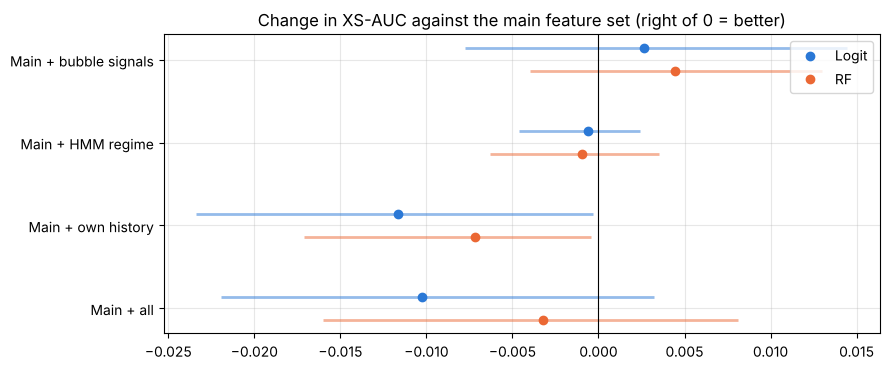

In [35]:
# Visual: change in ranking skill (XS-AUC) from each added feature group, Random Forest and Logit
t = abl_tests.reset_index()
fig, ax = plt.subplots(figsize=(9, 3.8))
for k, (fam, c) in enumerate([("Logit", MODEL_COLORS["Logit"]), ("RF", MODEL_COLORS["RandomForest"])]):
    d = t[t["Model"] == fam]
    yy = np.arange(len(d)) + (k - 0.5) * 0.28
    ax.hlines(yy, d["ΔXS-AUC lo"], d["ΔXS-AUC hi"], color=c, lw=2, alpha=0.5)
    ax.plot(d["ΔXS-AUC"], yy, "o", color=c, label=fam)
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(range(len(d))); ax.set_yticklabels(d["Variant vs Main"]); ax.invert_yaxis()
ax.set(title="Change in XS-AUC against the main feature set (right of 0 = better)"); ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

In [36]:
# 7.3 Other settings: target definition, unranked features, half-life (one change at a time)
for dd in (0.20, 0.40):
    lab = crash_label(rel_px, MAIN_H, dd).stack().rename(f"Crash_{MAIN_H}_dd{int(dd * 100)}")
    panel[lab.name] = lab.reindex(panel.index)
SPECS_2  = {m: MODEL_SPECS[m] for m in [BENCH_MODEL, MAIN_MODEL]}
RAW_SPEC = {BENCH_MODEL: ("logit", FEATS_RAW), MAIN_MODEL: ("rf", FEATS_RAW)}
main_lab = f"Crash_{MAIN_H}"
hl_name = lambda hl: "No time decay" if np.isinf(hl) else f"Half-life {hl:g} years"
SCENARIOS = {f"Baseline (relative {REL_DD:.0%}, {hl_name(HALF_LIFE).lower()})": PRED[MAIN_H],
             "Relative threshold 20%":          walk_forward(f"{main_lab}_dd20", SPECS_2, MAIN_H)[0],
             "Relative threshold 40%":          walk_forward(f"{main_lab}_dd40", SPECS_2, MAIN_H)[0],
             f"Absolute label ({ABS_DD:.0%})":  PRED_ABS,
             "Raw features (no ranks)":         walk_forward(main_lab, RAW_SPEC, MAIN_H, rows=panel.dropna(subset=FEATS_RAW))[0],
             **{hl_name(hl): walk_forward(main_lab, SPECS_2, MAIN_H, half_life=hl)[0] for hl in HALF_LIFE_GRID if hl != HALF_LIFE}}
rows = []
for name, pred in SCENARIOS.items():
    res = evaluate(early_warning(pred), list(SPECS_2))
    for m in SPECS_2:
        rows.append({"Scenario": name, "Model": m, **res.loc[m, ["N", "Crash rate", "XS-AUC", "Time-AUC", "AUC", "BSS", "BSS lo", "BSS hi"]].to_dict()})
robust = pd.DataFrame(rows).set_index(["Scenario", "Model"]).astype({"N": int})
robust.round(3)

N  Crash rate  XS-AUC  Time-AUC    AUC    BSS  BSS lo  BSS hi
Scenario                               Model                                                                          
Baseline (relative 30%, no time decay) Logit         28502       0.131   0.678     0.526  0.624  0.036   0.016   0.063
                                       RandomForest  28502       0.131   0.710     0.516  0.628  0.036   0.022   0.057
Relative threshold 20%                 Logit         28502       0.330   0.622     0.507  0.607  0.045   0.025   0.074
                                       RandomForest  28502       0.330   0.632     0.501  0.608  0.042   0.024   0.063
Relative threshold 40%                 Logit         28502       0.050   0.735     0.567  0.625  0.039   0.013   0.077
                                       RandomForest  28502       0.050   0.773     0.522  0.653  0.033   0.018   0.057
Absolute label (40%)                   Logit         28502       0.089   0.737     0.456  0.595  0.034   0.000   0.067
                                       RandomForest  28502       0.089   0.735     0.319  0.551  0.021   0.007   0.037
Raw features (no ranks)                Logit         28502       0.131   0.694     0.527  0.597  0.028  -0.003   0.059
                                       RandomForest  28502       0.131   0.684     0.540  0.615  0.030   0.007   0.053
Half-life 10 years                     Logit         28502       0.131   0.671     0.484  0.597  0.026   0.007   0.054
                                       RandomForest  28502       0.131   0.702     0.473  0.590  0.027   0.016   0.046
Half-life 20 years                     Logit         28502       0.131   0.677     0.507  0.611  0.032   0.013   0.060
                                       RandomForest  28502       0.131   0.707     0.496  0.611  0.033   0.019   0.054
Half-life 40 years                     Logit         28502       0.131   0.679     0.518  0.618  0.035   0.015   0.062
                                       RandomForest  28502       0.131   0.709     0.510  0.620  0.035   0.021   0.056

### What the ablation shows — the honest headline

- **No added feature group improves the ranking.** For both the Logit and the Random Forest, the change in XS-AUC from adding bubble signals, the HMM regime or own-history features is within about ±0.01, every interval includes 0 or lies below it, and **nothing is significant after the FDR adjustment**.
- **Bubble signals add nothing measurable** (Random Forest: +0.004 XS-AUC). The GSADF test, the small-firm tilt and rising volatility in a run-up do not help to rank industries beyond what past return and volatility already say.
- **The market regime does not create timing skill.** Adding the HMM probabilities leaves Time-AUC unchanged or slightly lower. The regime describes the present state of the market; it does not say when severe drawdowns will be frequent.
- **Own-history features, the idea aimed at timing, do not help either,** and they make the Logit's probabilities worse.
- **The choice of target matters more than the choice of features.** With the absolute 40% target the ranking looks better (XS-AUC 0.735) but timing turns perverse (Time-AUC 0.32): the level of predicted risk is high *after* a wave of drawdowns, not before one. The relative target removes market-wide falls and brings Time-AUC back to 0.5, which is why it is the headline.
- **Ranks help the probabilities, time decay does not.** Without cross-sectional ranks the Random Forest's XS-AUC falls from 0.710 to 0.684. The validation years chose "no time decay", and the shorter half-lives are indeed worse on the test years.

So the honest reading is: **the ranking is driven by volatility and past return; the more elaborate signals (GSADF, HMM, own history) describe the market but do not improve the forecast.** They are kept in the product as context, not as signals.

## 8. Rigorous Validation

A single headline number can flatter a model. Before trusting the ranking we stress-test it five ways: **stability across eras**, a head-to-head with the **volatility benchmark**, the **stability of the levels and the choice of a signal rule**, an event-level check of the **run-up pattern** from the literature, and what happens when someone **acts on the signal**. A final check measures **overfitting**.

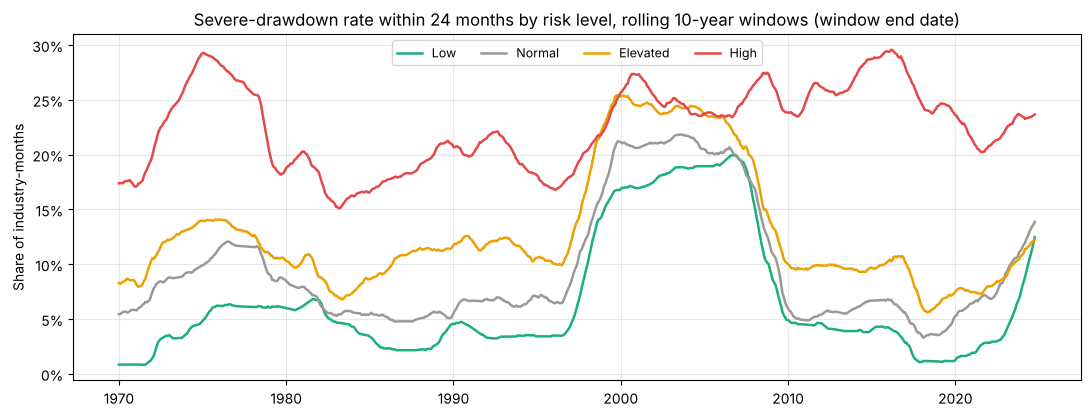

Level,Low,Normal,Elevated,High,Industry-months,Severe drawdowns,XS-AUC,Rates rise Low to High
Period,,,,,,,,
1960–1979,0.036,0.070,0.093,0.181,8269,798,0.719,True
1980–1999,0.108,0.135,0.187,0.232,9664,1609,0.681,True
2000–2024,0.071,0.089,0.096,0.242,10569,1333,0.729,True


In [37]:
# 8.1 Does the ordering of the levels hold in every 20-year period?
T["Period"] = pd.cut(t_dates.year, [1959, 1979, 1999, 2100], labels=["1960–1979", "1980–1999", "2000–2024"])
period_rate = T.groupby(["Period", "Level"], observed=False)["y"].mean().unstack("Level")
period_table = period_rate.assign(**{"Industry-months": T.groupby("Period", observed=False).size(),
                                     "Severe drawdowns": T.groupby("Period", observed=False)["y"].sum().astype(int),
                                     "XS-AUC": [xs_auc(g, MAIN_MODEL).mean() for _, g in T.groupby("Period", observed=False)],
                                     "Rates rise Low to High": (period_rate.diff(axis=1).iloc[:, 1:] > 0).all(axis=1)})
monthly = T.groupby(["Date", "Level"], observed=False)["y"].agg(["sum", "size"]).unstack("Level")
rolling = monthly["sum"].rolling(120, min_periods=120).sum() / monthly["size"].rolling(120, min_periods=120).sum()
fig, ax = plt.subplots(figsize=(13, 4.5))
for lvl, c in zip(LEVELS, ["#1baf7a", "#9a9994", "#eda100", "#e34948"]):
    ax.plot(rolling[lvl], color=c, lw=1.8, label=lvl)
ax.set(title="Severe-drawdown rate within 24 months by risk level, rolling 10-year windows (window end date)", ylabel="Share of industry-months")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
ax.legend(ncol=4, fontsize=9)
ax.grid(True, alpha=0.3)
save(fig, "risk_levels_over_time")
period_table.round(3)

In [38]:
# 8.2 Head-to-head with a volatility ranking: XS-AUC, High level, skill inside volatility thirds, matched control
vol_rows = []
for label, df in [(f"Relative drawdown >= {REL_DD:.0%} (Risk Ranking)", EW[MAIN_H]), (f"Absolute drawdown >= {ABS_DD:.0%}", EW_ABS)]:
    res = evaluate(df, MODELS)
    for m in MODELS:
        row = {"Target": label, "Model": m, **res.loc[m, ["XS-AUC", "XS-AUC lo", "XS-AUC hi"]].to_dict()}
        if m != VOL_MODEL:
            d = paired_diff(df, m, VOL_MODEL)
            row.update({"ΔXS-AUC vs Logit-Vol": d["ΔXS-AUC"], "Δ lo": d["ΔXS-AUC lo"], "Δ hi": d["ΔXS-AUC hi"]})
        vol_rows.append(row)
vol_test = pd.DataFrame(vol_rows).set_index(["Target", "Model"])

Tv = T[T["Level (vol-only)"].notna()]
yv, c_rf, c_vol = Tv["y"].values, Tv["Level"].cat.codes.values, Tv["Level (vol-only)"].cat.codes.values
stat = lambda ix: [yv[ix][c_rf[ix] == 3].mean(), yv[ix][c_vol[ix] == 3].mean(), yv[ix][c_rf[ix] == 3].mean() - yv[ix][c_vol[ix] == 3].mean(),
                   yv[ix][c_rf[ix] == 0].mean(), yv[ix][c_vol[ix] == 0].mean(), yv[ix][c_rf[ix] == 0].mean() - yv[ix][c_vol[ix] == 0].mean()]
pt, lo, hi, _ = month_boot(Tv, stat)
level_vs_vol = pd.DataFrame({"Rate": pt, "95% lo": lo, "95% hi": hi},
                            index=[f"High level — {MAIN_MODEL}", "High level — volatility ranking", "High level — difference",
                                   f"Low level — {MAIN_MODEL}", "Low level — volatility ranking", "Low level — difference"])
level_vs_vol.loc["Share of High-level rows that are also High in the volatility ranking", "Rate"] = (c_vol[c_rf == 3] == 3).mean()

vol6_r = panel["Vol6_R"].reindex(EW[MAIN_H].index)
rows = []
for name, sel in {"Low volatility third": vol6_r <= 1 / 3, "Middle third": (vol6_r > 1 / 3) & (vol6_r <= 2 / 3), "High volatility third": vol6_r > 2 / 3}.items():
    res = evaluate(EW[MAIN_H][sel], MODELS)
    for m in MODELS:
        rows.append({"Volatility group": name, "Model": m, **res.loc[m, ["N", "Crash rate", "XS-AUC", "XS-AUC lo", "XS-AUC hi"]].to_dict()})
within_vol = pd.DataFrame(rows).set_index(["Volatility group", "Model"]).astype({"N": int}).rename(columns={"Crash rate": "Severe-drawdown rate"})

def matched_control(df, flag):
    """Flagged rows against non-flagged rows in the same bin of 24M return (5) x volatility rank (5)."""
    d = df.join(panel["Vol6_R"]).assign(flag=flag).dropna(subset=["y", "R24", "Vol6_R", "flag"]).sort_index()
    y, a = d["y"].values, d["flag"].values.astype(bool)
    b = (5 * pd.qcut(d["R24"], 5, labels=False) + pd.cut(d["Vol6_R"], 5, labels=False)).values
    def stat(ix):
        yy, aa, bb = y[ix], a[ix], b[ix]
        ctrl = pd.Series(yy[~aa]).groupby(bb[~aa]).mean().reindex(bb[aa]).values
        has = np.isfinite(ctrl)
        return [yy[aa][has].mean(), ctrl[has].mean(), yy[aa][has].mean() - ctrl[has].mean()]
    pt, lo, hi, _ = month_boot(d, stat)
    return {"Flagged rows": int(a.sum()), "Rate when flagged": pt[0], "Matched control": pt[1], "Difference": pt[2], "Diff lo": lo[2], "Diff hi": hi[2]}

control_table = pd.DataFrame({f"High level — {MAIN_MODEL}": matched_control(T, T["Level"] == "High"),
                              "High level — volatility ranking": matched_control(Tv, Tv["Level (vol-only)"] == "High")}).T.astype({"Flagged rows": int})
display(vol_test.round(3), level_vs_vol.round(3), within_vol.round(3), control_table.round(3))

XS-AUC  XS-AUC lo  XS-AUC hi  ΔXS-AUC vs Logit-Vol   Δ lo   Δ hi
Target                                  Model                                                                         
Relative drawdown >= 30% (Risk Ranking) Logit-Vol      0.703      0.666      0.742                   NaN    NaN    NaN
                                        Logit          0.678      0.645      0.724                -0.025 -0.044  0.001
                                        RandomForest   0.710      0.682      0.742                 0.007 -0.017  0.040
Absolute drawdown >= 40%                Logit-Vol      0.760      0.688      0.819                   NaN    NaN    NaN
                                        Logit          0.737      0.675      0.800                -0.023 -0.044  0.002
                                        RandomForest   0.735      0.668      0.790                -0.024 -0.045  0.001

,Rate,95% lo,95% hi
High level — RandomForest,0.221,0.177,0.262
High level — volatility ranking,0.232,0.180,0.276
High level — difference,-0.011,-0.024,0.006
Low level — RandomForest,0.073,0.030,0.109
Low level — volatility ranking,0.078,0.034,0.119
Low level — difference,-0.005,-0.020,0.007
Share of High-level rows that are also High in the volatility ranking,0.683,NaN,NaN


N  Severe-drawdown rate  XS-AUC  XS-AUC lo  XS-AUC hi
Volatility group      Model                                                                 
Low volatility third  Logit-Vol     9869                 0.082   0.591      0.517      0.684
                      Logit         9869                 0.082   0.553      0.479      0.644
                      RandomForest  9869                 0.082   0.606      0.550      0.669
Middle third          Logit-Vol     9735                 0.105   0.558      0.490      0.622
                      Logit         9735                 0.105   0.528      0.472      0.596
                      RandomForest  9735                 0.105   0.596      0.546      0.658
High volatility third Logit-Vol     8898                 0.214   0.677      0.635      0.715
                      Logit         8898                 0.214   0.637      0.603      0.686
                      RandomForest  8898                 0.214   0.670      0.628      0.712

,Flagged rows,Rate when flagged,Matched control,Difference,Diff lo,Diff hi
High level — RandomForest,7402,0.221,0.160,0.061,0.025,0.105
High level — volatility ranking,7402,0.232,0.142,0.090,0.039,0.130


In [39]:
# 8.3 How stable are the levels from month to month?
lv = LV["Level"].unstack("Industry")                                           # month x industry; missing when already falling
pairs = pd.DataFrame({"This month": lv.stack(), "Next month": lv.shift(-1).stack()}).dropna()
transition = pd.crosstab(pairs["This month"], pairs["Next month"], normalize="index").reindex(index=LEVELS, columns=LEVELS)
is_high = lv.eq("High")
spells = np.array([len(g) for c in is_high for _, g in is_high[c].groupby((is_high[c] != is_high[c].shift()).cumsum()) if g.iloc[0]])
rk = LV["Rank"].unstack("Industry")
stability = pd.Series({"Same level next month": (pairs["This month"] == pairs["Next month"]).mean(),
                       "Moves two or more levels in one month": (abs(pairs["This month"].cat.codes - pairs["Next month"].cat.codes) >= 2).mean(),
                       "High spells lasting one month only": (spells == 1).mean(),
                       "Median length of a High spell (months)": np.median(spells),
                       **{f"Rank correlation with the ranking {k} months later": rk.corrwith(rk.shift(-k), axis=1, method="spearman").mean() for k in (1, 3, 12)}},
                      name="Value").to_frame()
display(transition.round(3), stability.round(3))

Next month,Low,Normal,Elevated,High
This month,,,,
Low,0.807,0.167,0.022,0.003
Normal,0.154,0.667,0.165,0.014
Elevated,0.028,0.161,0.664,0.147
High,0.002,0.016,0.140,0.843


,Value
Same level next month,0.745
Moves two or more levels in one month,0.021
High spells lasting one month only,0.396
Median length of a High spell (months),2.000
Rank correlation with the ranking 1 months later,0.906
Rank correlation with the ranking 3 months later,0.816
Rank correlation with the ranking 12 months later,0.589


In [40]:
# 8.3b Signal rules: High this month vs confirmation rules (detection, false alarms, lead time)
def drawdown_events(px, dd):
    below = px / px.rolling(24, min_periods=1).max() - 1 <= -dd
    out = []
    for ind in px.columns:
        last = None
        for d in below.index[below[ind].fillna(False)]:
            if last is None or (d.to_period("M") - last.to_period("M")).n > 24:
                out.append((ind, d))
                last = d
    return pd.DataFrame(out, columns=["Industry", "Onset"])

near = lv.isin(["Elevated", "High"])
RULES = {"A: High this month": is_high,
         "B: High two months in a row": is_high & is_high.shift(1, fill_value=False),
         "C: High or Elevated in 2 of the last 3 months": near.astype(int).rolling(3, min_periods=1).sum() >= 2,
         "D: High in 2 of the last 3 months": is_high.astype(int).rolling(3, min_periods=1).sum() >= 2}
Yw = LV["y"].unstack("Industry")
events = drawdown_events(rel_px, REL_DD)
events = events[(events["Onset"] >= lv.index[0] + pd.DateOffset(months=MAIN_H)) & events["Industry"].isin(lv.columns)]

def first_signal(sig, ind, onset):
    w = sig[ind].loc[onset - pd.DateOffset(months=MAIN_H):onset - pd.DateOffset(months=1)]
    return w[w].index.min() if w.any() else pd.NaT

first_a = [first_signal(RULES["A: High this month"], i, d) for i, d in zip(events["Industry"], events["Onset"])]
rows = {}
for name, sig in RULES.items():
    rated = lv.notna()
    sig = sig & rated
    hit = Yw.where(sig).stack()
    first = [first_signal(sig, i, d) for i, d in zip(events["Industry"], events["Onset"])]
    lead = [(d.to_period("M") - f.to_period("M")).n for d, f in zip(events["Onset"], first) if pd.notna(f)]
    wait = [(f.to_period("M") - a.to_period("M")).n for f, a in zip(first, first_a) if pd.notna(f) and pd.notna(a)]
    rows[name] = {"Industry-months flagged": sig.sum().sum() / rated.sum().sum(), "Severe-drawdown rate when flagged": hit.mean(),
                  "False-alarm rate": 1 - hit.mean(), "Events": len(events), "Events flagged in advance": len(lead) / len(events),
                  "Median lead time (months)": np.median(lead), "Mean extra wait vs rule A (months)": np.mean(wait)}
rule_table = pd.DataFrame(rows).T.astype({"Events": int})
rule_table.round(3)

,Industry-months flagged,Severe-drawdown rate when flagged,False-alarm rate,Events,Events flagged in advance,Median lead time (months),Mean extra wait vs rule A (months)
A: High this month,0.260,0.221,0.779,340,0.541,23.0,0.000
B: High two months in a row,0.208,0.231,0.769,340,0.476,23.0,1.235
C: High or Elevated in 2 of the last 3 months,0.490,0.174,0.826,340,0.679,24.0,-0.895
D: High in 2 of the last 3 months,0.246,0.223,0.777,340,0.494,24.0,0.452


In [41]:
# 8.4 Run-up pattern of Greenwood et al.: count each run-up once (episode level), with two intervals
def runup_flag(x):
    return (R24 >= x) & (Net24 >= x) & (R60 >= RUNUP_5Y) & eligible

def runup_episodes(flag):
    out = []
    for ind in INDS:
        last = None
        for d in flag.index[flag[ind]]:
            if last is None or (d.to_period("M") - last.to_period("M")).n > 24:
                out.append((ind, d))
            last = d
    return pd.DataFrame(out, columns=["Industry", "Date"])

def episode_outcomes(ep):
    """Outcome of each episode with a complete 24-month future window."""
    rows = []
    for ind, d in zip(ep["Industry"], ep["Date"]):
        px = price[ind].loc[d:].iloc[:MAIN_H + 1]
        if len(px) <= MAIN_H or px.isna().any():
            continue
        m = (1 + mkt.loc[d:].iloc[1:MAIN_H + 1]).cumprod()
        rows.append({"Industry": ind, "Date": d, "Severe drawdown": CRASH_ABS.at[d, ind],
                     "Months to peak": (px.idxmax().to_period("M") - d.to_period("M")).n, "Return to peak": px.max() / px.iloc[0] - 1,
                     "Return 12M": px.iloc[12] / px.iloc[0] - 1, "Return 24M": px.iloc[-1] / px.iloc[0] - 1,
                     "Return 24M net of market": px.iloc[-1] / px.iloc[0] - m.iloc[-1]})
    return pd.DataFrame(rows)

def wilson(k, n, z=1.96):
    p, d = k / n, 1 + z * z / n
    c, h = p + z * z / (2 * n), z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    return (c - h) / d, (c + h) / d

def year_cluster_ci(e, seed=SEED, n_boot=2000):
    rng, years, x = np.random.default_rng(seed), e["Date"].dt.year.values, e["Severe drawdown"].values
    uniq = np.unique(years)
    draws = [x[np.concatenate([np.flatnonzero(years == yr) for yr in rng.choice(uniq, len(uniq))])].mean() for _ in range(n_boot)]
    return np.percentile(draws, [2.5, 97.5])

BASE_ABS = CRASH_ABS.where(eligible).stack().mean()                            # all eligible industry-months
strict = runup_flag(RUNUP_2Y)
EP = episode_outcomes(runup_episodes(strict))
k, n = int(EP["Severe drawdown"].sum()), len(EP)
runup_facts = pd.Series({
    "Flagged industry-months": int(strict.sum().sum()),
    "Episodes": len(runup_episodes(strict)),
    "Episodes with a complete 24-month outcome": n,
    "Distinct industries / calendar years": f"{EP['Industry'].nunique()} / {EP['Date'].dt.year.nunique()}",
    "Episodes followed by a severe drawdown": k,
    "Rate, counted per episode": round(k / n, 3),
    "Wilson 95% interval": "[{:.3f}, {:.3f}]".format(*wilson(k, n)),
    "Year-clustered bootstrap 95% interval": "[{:.3f}, {:.3f}]".format(*year_cluster_ci(EP)),
    "Base rate, all eligible industry-months": round(BASE_ABS, 3),
    "Ratio to the base rate": round(k / n / BASE_ABS, 1),
    "For comparison: rate counted per flagged month (overstated by overlap)": round(CRASH_ABS.where(strict).stack().mean(), 3)},
    name="Value", dtype=object).to_frame()
runup_facts

,Value
Flagged industry-months,334
Episodes,48
Episodes with a complete 24-month outcome,46
Distinct industries / calendar years,24 / 28
Episodes followed by a severe drawdown,19
"Rate, counted per episode",0.413
Wilson 95% interval,"[0.283, 0.557]"
Year-clustered bootstrap 95% interval,"[0.213, 0.592]"
"Base rate, all eligible industry-months",0.112
Ratio to the base rate,3.7


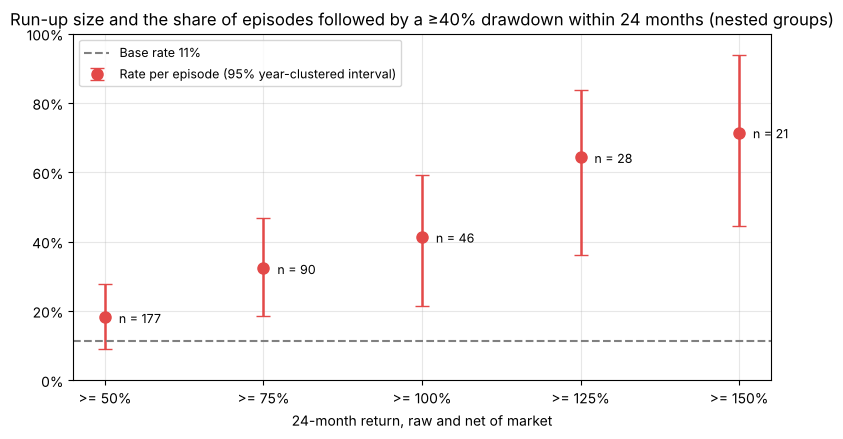

,Episodes,Severe drawdowns,Rate,Wilson lo,Wilson hi,Year-cluster lo,Year-cluster hi,p vs base rate,p adjusted (BH),Mean return 24M net of market,Median return 24M net of market
Run-up threshold,,,,,,,,,,,
>= 50%,177,32,0.181,0.131,0.244,0.090,0.278,0.004,0.004,0.041,-0.034
>= 75%,90,29,0.322,0.235,0.424,0.184,0.469,0.000,0.000,0.020,-0.037
>= 100%,46,19,0.413,0.283,0.557,0.213,0.592,0.000,0.000,-0.022,-0.125
>= 125%,28,18,0.643,0.458,0.793,0.360,0.838,0.000,0.000,-0.151,-0.160
>= 150%,21,15,0.714,0.500,0.862,0.444,0.938,0.000,0.000,-0.183,-0.214


In [42]:
# 8.4b Run-up size and the rate of severe drawdowns (nested groups, every threshold with its interval, BH-adjusted)
rows = []
for x in RUNUP_GRID:
    e = episode_outcomes(runup_episodes(runup_flag(x)))
    k, n = int(e["Severe drawdown"].sum()), len(e)
    lo_w, hi_w = wilson(k, n)
    lo_c, hi_c = year_cluster_ci(e)
    rows.append({"Run-up threshold": f">= {x:.0%}", "Episodes": n, "Severe drawdowns": k, "Rate": k / n, "Wilson lo": lo_w, "Wilson hi": hi_w,
                 "Year-cluster lo": lo_c, "Year-cluster hi": hi_c, "p vs base rate": stats.binomtest(k, n, BASE_ABS, alternative="greater").pvalue,
                 "Mean return 24M net of market": e["Return 24M net of market"].mean(), "Median return 24M net of market": e["Return 24M net of market"].median()})
runup_table = pd.DataFrame(rows).set_index("Run-up threshold")
runup_table.insert(runup_table.columns.get_loc("p vs base rate") + 1, "p adjusted (BH)", multipletests(runup_table["p vs base rate"], method="fdr_bh")[1])

fig, ax = plt.subplots(figsize=(9, 4.5))
xpos = np.arange(len(runup_table))
ax.errorbar(xpos, runup_table["Rate"], yerr=[runup_table["Rate"] - runup_table["Year-cluster lo"], runup_table["Year-cluster hi"] - runup_table["Rate"]],
            fmt="o", color="#e34948", ms=8, capsize=5, lw=1.8, label="Rate per episode (95% year-clustered interval)")
ax.axhline(BASE_ABS, color="gray", ls="--", label=f"Base rate {BASE_ABS:.0%}")
for x_, (n_, r_) in enumerate(zip(runup_table["Episodes"], runup_table["Rate"])):
    ax.annotate(f"n = {n_}", (x_, r_), xytext=(10, -4), textcoords="offset points", fontsize=9)
ax.set_xticks(xpos)
ax.set_xticklabels(runup_table.index)
ax.set(title="Run-up size and the share of episodes followed by a ≥40% drawdown within 24 months (nested groups)",
       xlabel="24-month return, raw and net of market", ylim=(0, 1))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
ax.legend(loc="upper left", fontsize=9)
ax.grid(True, alpha=0.3)
save(fig, "runup_watch_thresholds")
runup_table.round(3)

In [43]:
# 8.4c Out-of-sample: episodes after 2014, which the original paper could not use
EP["Period"] = pd.cut(EP["Date"].dt.year, [1900, 1959, 1989, 2014, 2100], labels=["to 1959", "1960–1989", "1990–2014", "2015 onwards (out of sample)"])
runup_periods = EP.groupby("Period", observed=False)["Severe drawdown"].agg(Episodes="size", Drawdowns="sum").astype(int)
runup_periods["Rate"] = runup_periods["Drawdowns"] / runup_periods["Episodes"]
runup_periods[["Wilson lo", "Wilson hi"]] = [wilson(k, n) for k, n in zip(runup_periods["Drawdowns"], runup_periods["Episodes"])]
recent = EP.loc[EP["Date"].dt.year >= 2015, ["Industry", "Date", "Severe drawdown", "Return 24M", "Return 24M net of market"]].assign(
    Date=lambda d: d["Date"].dt.strftime("%Y-%m")).set_index("Industry")
display(runup_periods.round(3), recent.round(2))

,Episodes,Drawdowns,Rate,Wilson lo,Wilson hi
Period,,,,,
to 1959,7,4,0.571,0.250,0.842
1960–1989,19,8,0.421,0.231,0.637
1990–2014,13,6,0.462,0.232,0.709
2015 onwards (out of sample),7,1,0.143,0.026,0.513


,Date,Severe drawdown,Return 24M,Return 24M net of market
Industry,,,,
Toys,2020-12,1.0,-0.67,-0.66
Fun,2018-06,0.0,-0.07,-0.24
Cnstr,2024-09,0.0,0.22,-0.14
Steel,2022-02,0.0,0.36,0.18
Autos,2020-08,0.0,0.55,0.41
Mines,2022-03,0.0,0.25,0.06
Oil,2022-05,0.0,0.14,-0.18


In [44]:
# 8.4d What happened after a run-up was flagged
after = pd.DataFrame({name: {"Episodes": len(g_), "Months to peak (mean)": g_["Months to peak"].mean(), "Months to peak (median)": g_["Months to peak"].median(),
                             "Return to peak": g_["Return to peak"].mean(), "Return 12M": g_["Return 12M"].mean(), "Return 24M": g_["Return 24M"].mean(),
                             "Return 24M net of market": g_["Return 24M net of market"].mean()}
                      for name, g_ in [("All episodes", EP), ("Followed by a severe drawdown", EP[EP["Severe drawdown"] == 1]),
                                       ("Not followed by one", EP[EP["Severe drawdown"] == 0])]}).T.astype({"Episodes": int})
after.round(2)

,Episodes,Months to peak (mean),Months to peak (median),Return to peak,Return 12M,Return 24M,Return 24M net of market
All episodes,46,12.37,12.5,0.44,0.08,0.05,-0.02
Followed by a severe drawdown,19,5.32,3.0,0.25,-0.10,-0.42,-0.33
Not followed by one,27,17.33,18.0,0.58,0.20,0.38,0.20


In [45]:
# 8.5 Acting on the signal: portfolio engine (weights at t earn the return of t+1, net of 10 bps) and a long-short test
def run_portfolio(w, cost_bps=COST_BPS):
    r_next  = ret.shift(-1).reindex(index=w.index, columns=w.columns)              # return of month t+1
    rf_next = RF_M.shift(-1).reindex(w.index)
    keep = r_next.notna().any(axis=1) & rf_next.notna()
    Wt, R, F = w[keep].fillna(0.0).values, r_next[keep].fillna(0.0).values, rf_next[keep].values
    assert (Wt >= -1e-12).all() and (Wt.sum(axis=1) <= 1 + 1e-9).all(), "weights must be long-only and sum to at most 1"
    gross, turn, prev = np.zeros(len(Wt)), np.zeros(len(Wt)), np.zeros(Wt.shape[1])
    for t in range(len(Wt)):
        turn[t]  = np.abs(Wt[t] - prev).sum()                                      # trade at the end of month t
        gross[t] = Wt[t] @ R[t] + (1 - Wt[t].sum()) * F[t]
        prev = Wt[t] * (1 + R[t]) / (1 + gross[t])                                 # weights after drifting through t+1
    idx = w.index[keep] + pd.offsets.MonthEnd(1)                                   # month in which the return is earned
    return pd.DataFrame({"gross": gross, "cost": cost_bps / 1e4 * turn, "net": gross - cost_bps / 1e4 * turn,
                         "turnover": turn, "cash": 1 - Wt.sum(axis=1)}, index=idx)

def perf(r):
    r = r.dropna()
    rf, m_ex = RF_M.reindex(r.index), (mkt - RF_M.reindex(mkt.index)).reindex(r.index)
    cum = (1 + r).cumprod()
    cagr, vol = cum.iloc[-1] ** (12 / len(r)) - 1, r.std() * np.sqrt(12)
    mdd = (cum / cum.cummax().clip(lower=1.0) - 1).min()
    down = m_ex < 0
    return {"Ann. return": r.mean() * 12, "CAGR": cagr, "Ann. vol": vol, "Sharpe": (r - rf).mean() * 12 / vol,
            "Max drawdown": mdd, "Calmar": cagr / abs(mdd), "CVaR 5% (monthly)": -r[r <= r.quantile(0.05)].mean(),
            "Downside beta": np.cov((r - rf)[down], m_ex[down])[0, 1] / m_ex[down].var()}

def diff_ci(r, ctrl):
    d = (r - ctrl).dropna().values
    lo, hi = np.percentile([d[ix].mean() * 12 for ix in block_positions(len(d))], [2.5, 97.5])
    return {"Δ ann. return vs control": d.mean() * 12, "Δ lo": lo, "Δ hi": hi}

P_wide    = PRED[MAIN_H][MODELS].where(~PRED[MAIN_H]["Masked"]).unstack("Industry")   # P of industries not already falling
cap_wide  = PRED[MAIN_H]["MCap"].unstack("Industry")
BASE_W = {"Cap-weighted": cap_wide.div(cap_wide.sum(axis=1), axis=0),
          "Equal-weighted": cap_wide.notna().div(cap_wide.notna().sum(axis=1), axis=0)}

def quintile_ls(model):
    q = P_wide[model].rank(axis=1, pct=True)
    legs = [run_portfolio(sel.div(sel.sum(axis=1), axis=0).astype(float)) for sel in (q <= 0.2, q >= 0.8)]
    return (legs[0]["gross"] - legs[1]["gross"] - legs[0]["cost"] - legs[1]["cost"]).rename(model)

rows = {}
for m in MODELS:
    ls = quintile_ls(m)
    X = ff[["Mkt-RF", "SMB", "HML"]].reindex(ls.index)
    capm = sm.OLS(ls, sm.add_constant(X[["Mkt-RF"]]), missing="drop").fit(cov_type="HAC", cov_kwds={"maxlags": 12})
    ff3  = sm.OLS(ls, sm.add_constant(X), missing="drop").fit(cov_type="HAC", cov_kwds={"maxlags": 12})
    rows[m] = {"Months": len(ls), "Ann. return (x12)": ls.mean() * 12, "Ann. vol (x sqrt12)": ls.std() * np.sqrt(12),
               "CAPM alpha (ann.)": capm.params["const"] * 12, "t CAPM": capm.tvalues["const"], "Market beta": capm.params["Mkt-RF"],
               "FF3 alpha (ann.)": ff3.params["const"] * 12, "t FF3": ff3.tvalues["const"]}
ls_table = pd.DataFrame(rows).T.astype({"Months": int})
ls_table.round(3)

,Months,Ann. return (x12),Ann. vol (x sqrt12),CAPM alpha (ann.),t CAPM,Market beta,FF3 alpha (ann.),t FF3
Logit-Vol,800,-0.027,0.134,0.004,0.236,-0.433,-0.002,-0.090
Logit,800,-0.056,0.137,-0.027,-1.512,-0.406,-0.030,-1.689
RandomForest,800,-0.052,0.121,-0.035,-2.201,-0.236,-0.037,-2.303


In [46]:
# 8.5b Reducing weight in High-level industries: exposure to severe drawdowns vs return and drawdown
high_w = lv.eq("High").reindex(index=cap_wide.index, columns=cap_wide.columns).fillna(False)
rescale = lambda w: w.div(w.sum(axis=1), axis=0)

def exposure(w):
    """Share of the equity weight held in industries that go on to a severe drawdown (months with a known outcome)."""
    known = Yw.reindex(index=w.index, columns=w.columns)
    ok = known.notna().any(axis=1)
    return ((w * known).sum(axis=1) / w.where(known.notna()).sum(axis=1))[ok]

bt_rows, BT = [], {}
for scheme, base in BASE_W.items():
    plans = {"Control": base,
             "High level halved": rescale(base.where(~high_w, base * 0.5)),
             "High level removed, weight to other industries": rescale(base.where(~high_w, 0.0)),
             "High level removed, weight to T-bills": base.where(~high_w, 0.0)}
    plans["Exposure-matched control"] = base * plans["High level removed, weight to T-bills"].sum(axis=1).mean()
    for name, w in plans.items():
        BT[(scheme, name)] = (w, run_portfolio(w))
bt_common = sorted(set.intersection(*[set(r.index) for _, r in BT.values()]))
for (scheme, name), (w, r) in BT.items():
    w0, r0 = BT[(scheme, "Control")]
    net, ctrl = r["net"].reindex(bt_common), r0["net"].reindex(bt_common)
    e, e0 = exposure(rescale(w)), exposure(w0)
    d = (e - e0).values
    row = {"Weighting": scheme, "Adjustment": name, "Severe-drawdown exposure": e.mean(), **{k: perf(net)[k] for k in ["CAGR", "Ann. vol", "Sharpe", "Max drawdown", "CVaR 5% (monthly)"]},
           "Avg. T-bill share": r["cash"].reindex(bt_common).mean(), "Turnover (one-way, /yr)": r["turnover"].reindex(bt_common).mean() * 6}
    if name != "Control":
        lo, hi = np.percentile([d[ix].mean() for ix in block_positions(len(d))], [2.5, 97.5])
        row.update({"Δ exposure": d.mean(), "Δ exp. lo": lo, "Δ exp. hi": hi, **diff_ci(net, ctrl)})
    bt_rows.append(row)
BT_TABLE = pd.DataFrame(bt_rows).set_index(["Weighting", "Adjustment"])
print(f"Common sample: {bt_common[0]:%Y-%m} to {bt_common[-1]:%Y-%m} ({len(bt_common)} months), net of {COST_BPS} bps per unit traded")
BT_TABLE.round(3)

Common sample: 1960-02 to 2026-09 (800 months), net of 10 bps per unit traded


Severe-drawdown exposure   CAGR  Ann. vol  Sharpe  Max drawdown  CVaR 5% (monthly)  Avg. T-bill share  Turnover (one-way, /yr)  Δ exposure  Δ exp. lo  Δ exp. hi  \
Weighting      Adjustment                                                                                                                                                                                                         
Cap-weighted   Control                                                            0.099  0.108     0.153   0.472        -0.500              0.096              0.000                    0.255         NaN        NaN        NaN   
               High level halved                                                  0.093  0.105     0.152   0.458        -0.504              0.096             -0.000                    0.541      -0.006     -0.011     -0.002   
               High level removed, weight to other industries                     0.085  0.100     0.151   0.427        -0.511              0.097              0.000                    1.007      -0.015     -0.027     -0.005   
               High level removed, weight to T-bills                              0.085  0.090     0.124   0.417        -0.464              0.080              0.199                    0.663      -0.015     -0.027     -0.005   
               Exposure-matched control                                           0.099  0.097     0.123   0.472        -0.420              0.076              0.199                    0.207       0.000     -0.000      0.000   
Equal-weighted Control                                                            0.138  0.112     0.168   0.467        -0.526              0.106             -0.000                    0.216         NaN        NaN        NaN   
               High level halved                                                  0.128  0.108     0.167   0.448        -0.533              0.105              0.000                    0.509      -0.010     -0.014     -0.008   
               High level removed, weight to other industries                     0.114  0.103     0.165   0.422        -0.543              0.105              0.000                    0.921      -0.024     -0.032     -0.018   
               High level removed, weight to T-bills                              0.114  0.093     0.134   0.414        -0.495              0.086              0.229                    0.685      -0.024     -0.032     -0.018   
               Exposure-matched control                                           0.138  0.099     0.129   0.467        -0.428              0.081              0.229                    0.171       0.000      0.000      0.000   

                                                               Δ ann. return vs control   Δ lo   Δ hi  
Weighting      Adjustment                                                                              
Cap-weighted   Control                                                              NaN    NaN    NaN  
               High level halved                                                 -0.003 -0.005 -0.000  
               High level removed, weight to other industries                    -0.008 -0.015 -0.001  
               High level removed, weight to T-bills                             -0.021 -0.031 -0.009  
               Exposure-matched control                                          -0.014 -0.021 -0.007  
Equal-weighted Control                                                              NaN    NaN    NaN  
               High level halved                                                 -0.004 -0.006 -0.002  
               High level removed, weight to other industries                    -0.009 -0.014 -0.004  
               High level removed, weight to T-bills                             -0.023 -0.033 -0.015  
               Exposure-matched control                                          -0.018 -0.026 -0.009

In [47]:
# 8.6 Overfitting: AUC inside a training year vs the following test year
rows = []
for H in H_LIST:
    ew_y = EW[H].assign(Year=EW[H].index.get_level_values("Date").year)
    for m in MODELS:
        oos = pd.Series({yr: roc_auc_score(g["y"], g[m]) for yr, g in ew_y.groupby("Year") if g["y"].nunique() == 2})
        ins = INSAMPLE[H].query("Model == @m").set_index("Year")["AUC in-sample"].reindex(oos.index)
        rows.append({"Horizon (months)": H, "Model": m, "Fits": len(oos), "AUC in-sample": ins.mean(),
                     "AUC next year": oos.mean(), "Gap": ins.mean() - oos.mean()})
overfit = pd.DataFrame(rows).set_index(["Horizon (months)", "Model"])
overfit.round(3)

Fits  AUC in-sample  AUC next year    Gap
Horizon (months) Model                                                  
6                Logit-Vol       33          0.882          0.867  0.015
                 Logit           33          0.892          0.837  0.055
                 RandomForest    33          0.955          0.862  0.093
12               Logit-Vol       57          0.736          0.798 -0.062
                 Logit           57          0.773          0.761  0.011
                 RandomForest    57          0.850          0.781  0.069
24               Logit-Vol       65          0.666          0.700 -0.033
                 Logit           65          0.671          0.670  0.001
                 RandomForest    65          0.728          0.706  0.022

### What the validation tells us

- **The ranking is stable across eras.** The levels are ordered Low → High in all three 20-year periods, and XS-AUC is 0.72, 0.68 and 0.73. The *height* of the rates moves with the times (High: 18% to 24%), so a level is a guide to relative risk, not a forecast of a number.
- **H2 is rejected: the model does not beat a volatility ranking.** XS-AUC differs by +0.007 (interval −0.017 to +0.040). The High level of a plain volatility ranking has a slightly *higher* rate, 23.2% against 22.1% (difference −1.1%, interval −2.4% to +0.6%). Some skill survives inside volatility groups (XS-AUC 0.60–0.67 for the Random Forest) and against a control matched on return and volatility (22.1% against 16.0%), but the volatility-only model shows the same. The value of the work is a tested, monthly, industry-level ranking with its history attached, not a better model than traditional risk measures.
- **Levels are stable; confirmation is a dial, not a fix.** 74.5% of industries keep their level the next month and only 2% move two levels. Requiring two months at High lowers the false-alarm rate only from 77.9% to 76.9% and cuts the share of events flagged in advance from 54.1% to 47.6%. The report therefore shows every High signal and labels it `Watch` or `Confirmed`.
- **The run-up pattern is real in history but thinly validated.** Counted once per episode, 19 of 46 run-ups (41%, interval 21–59%) were followed by an absolute drawdown of 40% or more, against a base rate of 11%. Counting every flagged month would have given 55%, an overstatement caused by overlap. The rate rises with the size of the run-up, up to 71% for run-ups of 150% or more, but those groups are nested and small. **After 2014 only 1 of 7 episodes was followed by a severe drawdown.** Prices peaked about 12 months after the flag, 44% higher on average. This is a historical pattern with limited out-of-sample support, not an early-warning signal.
- **Acting mechanically on the signal costs return.** Industries ranked risky earned *more* on average (long–short alpha −3.7% a year, t = −2.3). Removing High-level industries from a cap-weighted portfolio lowers the share of the portfolio in industries that go on to a severe drawdown from 9.9% to 8.5%, but costs about 0.8% a year and does not improve the maximum drawdown. The tool supports a risk review; it is not a trading rule.
- **Overfitting is small at 24 months** (Random Forest gap 0.02) and largest at 6 months (0.09), which is one reason the 24-month horizon is the headline.

## 9. Deployment

The model is delivered as a **monthly risk report** for a portfolio manager. Each month it shows, for every industry that is High, inside a run-up, or changed level: the current and previous level, whether a High signal is new (`Watch`) or confirmed, the historical rate of that level with its sample size, the run-up size, the contributing factors, and the data as-of date. A client can also pass in portfolio weights to see how much of the portfolio sits in each level.

The report is decision support. It does not produce a portfolio score, a probability of loss or a trade.

In [48]:
# 9.1 Portfolio exposure by risk level (illustrative portfolio, not a client portfolio)
runup_size = sum(runup_flag(x).astype(int) for x in RUNUP_GRID)                                      # number of thresholds passed
RUNUP_LABEL = runup_size.replace(dict(enumerate(["—"] + [f">= {x:.0%}" for x in RUNUP_GRID])))
months_high = is_high.apply(lambda s: s.astype(int).groupby((~s).cumsum()).cumsum())                 # consecutive months at High
STATUS = pd.DataFrame(np.select([months_high >= 2, months_high == 1], ["Confirmed", "Watch"], default="—"), index=lv.index, columns=lv.columns)

def exposure_review(weights, date):
    w = pd.Series(weights, dtype=float)
    w = w / w.sum()
    level = lv.loc[date].astype(object).reindex(w.index).fillna("Already falling")
    holdings = pd.DataFrame({"Weight": w, "Risk level": level, "High status": STATUS.loc[date].reindex(w.index),
                             "Run-up": RUNUP_LABEL.loc[date].reindex(w.index)})
    cap = LV["MCap"].xs(date, level="Date")
    market = (cap / cap.sum()).groupby(lv.loc[date].astype(object).fillna("Already falling")).sum()
    summary = pd.DataFrame({"Portfolio": w.groupby(level).sum(), "Market (cap-weighted)": market}).reindex(LEVELS + ["Already falling"]).fillna(0.0).rename_axis("Risk level")
    review = holdings[(holdings["Risk level"] == "High") | (holdings["Run-up"] != "—")].sort_values("Weight", ascending=False)
    return summary, holdings.sort_values("Weight", ascending=False), review

LAST = lv.index[-1]
EXAMPLE_PORTFOLIO = {"Softw": 0.15, "Chips": 0.15, "Banks": 0.12, "Drugs": 0.12, "Rtail": 0.10,
                     "Oil": 0.08, "Util": 0.08, "Hardw": 0.08, "Autos": 0.06, "Insur": 0.06}
exposure, holdings, review = exposure_review(EXAMPLE_PORTFOLIO, LAST)
print(f"Illustrative portfolio, data as of {LAST:%Y-%m-%d}")
display(exposure.round(3), review.round(3))

Illustrative portfolio, data as of 2026-09-30


,Portfolio,Market (cap-weighted)
Risk level,,
Low,0.37,0.369
Normal,0.08,0.104
Elevated,0.26,0.164
High,0.29,0.303
Already falling,0.00,0.060


,Weight,Risk level,High status,Run-up
Chips,0.15,High,Confirmed,>= 50%
Hardw,0.08,High,Confirmed,>= 100%
Autos,0.06,High,Confirmed,—


In [49]:
# 9.2 Contributing factors for the latest month (SHAP of the model fitted at the end of last year); not causes of a drawdown
now_rows = panel.xs(LAST, level="Date")
now_rows = now_rows[~now_rows["Masked"]]
SV_NOW = shap_values(FITTED[(LAST.year, MAIN_MODEL)], now_rows[FEATS_MAIN]).rename(columns=FEAT_LABEL)
DRIVERS = SV_NOW.apply(lambda r: "; ".join(f"{f} ({v:+.3f})" for f, v in r.nlargest(3).items() if v > 0), axis=1)

In [50]:
# 9.3 Market context for the latest month (supporting information, not a signal)
gs_now = ind_psy.loc[LAST]
cap_now = LV["MCap"].xs(LAST, level="Date") / LV["MCap"].xs(LAST, level="Date").sum()
context = pd.Series({
    "Data as of": f"{LAST:%Y-%m-%d}",
    "Models fitted on data to": f"{LAST.year - 1}-12-31",
    "Volatility regime (HMM)": regime_m["Regime"].iloc[-1],
    "P(High volatility), monthly average": round(regime_m["High volatility"].iloc[-1], 2),
    "Industries with a GSADF flag (explosive price behaviour)": f"{int(gs_now.sum())} of {int(gs_now.notna().sum())}: {', '.join(gs_now[gs_now == 1].index) or 'none'}",
    f"Industries in a run-up (>= {RUNUP_2Y:.0%})": ", ".join(strict.loc[LAST][strict.loc[LAST]].index) or "none",
    "Industries rated / already falling": f"{int(lv.loc[LAST].notna().sum())} / {int(LV['Masked'].xs(LAST, level='Date').sum())}",
    "High: confirmed / watch": f"{int((STATUS.loc[LAST] == 'Confirmed').sum())} / {int((STATUS.loc[LAST] == 'Watch').sum())}",
    "Industries whose level changed this month": int((lv.loc[LAST].astype(object).fillna("-") != lv.iloc[-2].astype(object).fillna("-")).sum()),
    "Largest industry weight in the market": f"{cap_now.idxmax()} {cap_now.max():.1%}"},
    name=f"Monthly Risk Report — {LAST:%B %Y}", dtype=object).to_frame()
context

,Monthly Risk Report — September 2026
Data as of,2026-09-30
Models fitted on data to,2025-12-31
Volatility regime (HMM),Normal volatility
"P(High volatility), monthly average",0.0
Industries with a GSADF flag (explosive price behaviour),1 of 38: Chips
Industries in a run-up (>= 100%),Hardw
Industries rated / already falling,31 / 7
High: confirmed / watch,6 / 2
Industries whose level changed this month,7
Largest industry weight in the market,Chips 22.8%


In [51]:
# 9.4 The monthly industry table
snap = LV.xs(LAST, level="Date")
cur, prev = lv.loc[LAST].astype(object), lv.iloc[-2].astype(object)
report = pd.DataFrame({
    "Sector": pd.Series(SECTOR_OF),
    "Risk level": cur.fillna("Already falling"),
    "Previous level": prev.fillna("Already falling"),
    "High status": STATUS.loc[LAST],
    "Months at High": months_high.loc[LAST],
    "Historical rate 24M": cur.map(LEVEL_RATE["Rate 24M"]),
    "Sample size": cur.map(LEVEL_RATE["Industry-months"]).astype("Int64"),
    "Run-up": RUNUP_LABEL.loc[LAST],
    "GSADF flag": gs_now.map({1.0: "Yes", 0.0: "—"}),
    "Key drivers": DRIVERS.replace("", "—"),
    "Market weight": cap_now,
    "Rank": snap["Rank"]}).reindex(snap.index)
show = (report["Risk level"] == "High") | (report["Run-up"] != "—") | (report["Risk level"] != report["Previous level"])
report[show].sort_values("Rank", ascending=False).drop(columns="Rank").fillna({"Key drivers": "—"}).round(3)

,Sector,Risk level,Previous level,High status,Months at High,Historical rate 24M,Sample size,Run-up,GSADF flag,Key drivers,Market weight
Industry,,,,,,,,,,,
Autos,Consumer Discretionary,High,High,Confirmed,2,0.221,7402,—,—,Volatility before the run-up (+0.107); Recent volatility (+0.070); Rise in volatility (+0.007),0.025
Hardw,Information Technology,High,High,Confirmed,6,0.221,7402,>= 100%,—,24M return net of market (+0.050); Price acceleration (+0.048); Recent volatility (+0.042),0.017
ElcEq,Industrials,High,Already falling,Watch,1,0.221,7402,—,—,Recent volatility (+0.083); Volatility before the run-up (+0.018); 24M return net of market (+0.017),0.003
Mines,Materials,High,High,Confirmed,39,0.221,7402,—,—,Recent volatility (+0.085); Volatility before the run-up (+0.015),0.005
Chips,Information Technology,High,High,Confirmed,4,0.221,7402,>= 50%,Yes,24M return net of market (+0.033); Price acceleration (+0.019); Growth in number of firms (+0.011),0.228
Cnstr,Industrials,High,High,Confirmed,12,0.221,7402,—,—,Volatility before the run-up (+0.024); Recent volatility (+0.012); Book-to-market (+0.005),0.006
LabEq,Information Technology,High,Elevated,Watch,1,0.221,7402,—,—,Recent volatility (+0.014),0.018
Toys,Consumer Discretionary,High,High,Confirmed,2,0.221,7402,—,—,Volatility before the run-up (+0.011); Rise in volatility (+0.006),0.001
BldMt,Materials,Elevated,High,—,0,0.126,7038,—,—,Volatility before the run-up (+0.020),0.004


**Reading the latest report (September 2026).**

- **Eight industries are at the High level**, six of them confirmed: Autos, Hardw, Mines, Chips, Cnstr and Toys. ElcEq and LabEq are new this month (`Watch`).
- **One industry is inside a strict run-up: Hardw**, up about 150% in 24 months. This is exactly the situation in which the ranking model is least reliable (§8.4), so the run-up flag and the risk level should be read as two separate signals.
- **Chips is 22.8% of total market value.** Any cap-weighted view of risk is close to a statement about that one industry, which is why the report shows the largest weight.
- **The market context is quiet:** the HMM is in the Normal-volatility regime and one industry carries a GSADF flag. Neither has predictive value (§7); they tell the reader what kind of market the relative levels are being read in.
- **The illustrative portfolio holds 29% in High-level industries**, about the same as the market (30%). The holdings to review are Chips, Hardw and Autos.

## 10. Conclusion

**Findings.**
- **Industries can be ranked by the risk of a severe drawdown (H1 supported).** Out of sample from 1960 to 2024, the Random Forest reaches XS-AUC 0.710 (interval 0.682–0.742). Turned into four levels, the rate of severe drawdowns rises from 7.3% (Low) to 22.1% (High), in every 20-year period.
- **The ranking is not better than a volatility ranking (H2 rejected).** A Logit on two volatility ranks reaches 0.703, and its High level has a slightly higher rate. Volatility accounts for about 60% of what the model uses.
- **Timing is not predictable.** Time-AUC is 0.52 (interval contains 0.5). Market-wide variables, including the HMM regime, do not change that.
- **Bubble signals do not help.** GSADF strength, small-firm tilt and rising volatility in a run-up add nothing after adjustment for multiple testing.
- **Large run-ups were followed by severe drawdowns about 3.7 times as often as usual** (41% against 11%, per episode), in line with Greenwood, Shleifer & You (2019), but the evidence after 2014 is 1 episode out of 7, and the model cannot tell which run-ups end badly.
- **Honest interpretation:** the project started as "detect bubbles and warn before the crash". The data support a narrower claim: *a monthly, tested ranking of where severe-drawdown risk is concentrated across industries, driven mainly by volatility and past return.* It informs position limits and due diligence; it does not time the market or add return.

**What made the model better (§5–§8).**
- Cross-sectional rank features, which keep the scale stable over a century and improved both ranking and probability accuracy.
- A target defined relative to the market, which removed market-wide falls and the perverse timing they caused.
- Walk-forward validation with an embargo, a nested choice of the half-life, and block-bootstrap intervals, so the result is credible rather than a single lucky split.
- Counting run-ups per episode instead of per month, which corrected an overstated rate (55% → 41%).

**Limitations.**
- **Not better than volatility.** A client with a volatility ranking already has most of this signal.
- **Relative levels.** A quarter of the industries is always High; about four in five High signals are not followed by a severe drawdown.
- **Choices made after earlier runs.** The target and the product framing were changed after seeing earlier results, so the headline numbers are not a pre-registered test.
- **Dependence.** Industries fall together and 24-month windows overlap; the effective sample is far smaller than 28,502 rows. The run-up evidence rests on 46 episodes.
- **Uniform thresholds.** The same 30% threshold for every industry favours volatile industries; a threshold scaled to each industry's volatility was not tested.
- **Data and scope.** 48 Fama–French portfolios that are not tradable funds, revised rather than real-time data, monthly frequency, and price-drawdown risk only (not liquidity, credit or valuation risk).
- **Correlation, not causation.** SHAP values describe the model's inputs, not what causes a drawdown.

**Future work.**
- A target scaled to each industry's own volatility, to test whether any skill remains once volatility is removed from the definition itself.
- LPPLS confidence indicators (Demirer et al., 2017; Zhao & Sornette), evaluated with the same walk-forward design, as a dedicated attempt at timing.
- A model fitted only on run-up episodes, with international sectors added to enlarge the sample.
- Business validation: interviews with portfolio managers, a comparison with existing risk tools, and a check of the data-licensing terms for commercial use.

**Disclaimer.** This is a decision-support analysis. It is not investment advice and not a recommendation to buy or sell any security. Historical rates are based on past out-of-sample classifications and are not guaranteed future outcomes.

**References**
- Greenwood, R., Shleifer, A., & You, Y. (2019). Bubbles for Fama. *Journal of Financial Economics*, 131(1), 20–43.
- Phillips, P. C. B., Shi, S., & Yu, J. (2015). Testing for multiple bubbles. *International Economic Review*, 56(4), 1043–1078.
- Demirer, R., Demos, G., Gupta, R., & Sornette, D. (2017). On the predictability of stock market bubbles: evidence from LPPLS confidence multi-scale indicators.
- Zhao, D., & Sornette, D. Bubbles for Fama from Sornette. Swiss Finance Institute Research Paper 21-94.